# Two-way time transfer between two boards (28 October 2026)

Boards **8873292600AB** (node A, 192.168.2.100) and **887329260072A** (node B, 192.168.2.99), RF-clock 1.3.0.10 on both, run `20261028_124958`: 600 s of two-way time transfer (TWTT) with both boards on one FS725, i.e. a **zero-baseline** measurement (true clock offset 0), so the measured θ is the system's own constant plus its noise.

**How the set-up got here.** The first two-board run (`TWTT_two_board_Oct_27.ipynb`) found the B → A direction weak, noisy and stepping. Two faults in that path were found and fixed on 28 October:
1. **Mismatched attenuators**: 20 dB in B → A against 10 dB in A → B. Both were replaced by 5 dB. That fixed the level and the per-second noise, but not the steps (run `20261028_124958`).
2. **A loose connector** in the B → A path. Once it was reseated the steps and the level drops disappeared (run `20261028_123745`, θ standard deviation 1.0 ps over 10 minutes; it had also added about 1 ns to B → A).

This notebook analyses a **repeat run with the fixed set-up**, and compares it with the run before it to check that the constant comes back after the boards are restarted (each run reloads the overlay and redoes the clocks and MTS on both boards). Section 9 lists all the runs of the two days.

The method, the equations and the correlation are explained in `TWTT_selftest_Oct_27.ipynb`; section 5 here also works one θ out step by step from the raw data.

**Contents**
1. Set-up and commands
2. The data: one second recomputed from the logged ticks and peaks
3. Completeness and signal quality
4. The two one-way measurements
5. The clock offset θ, with a worked example from the raw data
6. The one-way delay
7. Stability with averaging (standard deviation of the mean, Allan deviation)
8. The saved captures: received levels of the two directions
9. Repeatability and the history of the two-board runs
10. Comparison with the one-board self-test
11. Summary
12. Report-ready results: key numbers, figures and captions

## 1. Set-up and commands

| | Node A: 8873292600AB | Node B: 887329260072A |
|---|---|---|
| Role | listens for B; transmits in slot AB (PPS + 100 ms), receives in slot BA (PPS + 600 ms) | connects to A; receives in slot AB, transmits in slot BA |
| 10 MHz | EPG1 REF OUT → resistive splitter → external reference | the same splitter, other port |
| PPS | FS725 1PPS → EPG1 → **output 1** (0.52 ns actual delay) → J7 | → **output 2** (7.48 ns actual delay) → J7; the two PPS cables differ slightly |
| RF out | DAC_A → band-pass filter → **5 dB** attenuator → **B's ADC_B** (direction AB) | DAC_A → band-pass filter → **5 dB** attenuator → **A's ADC_B** (direction BA; loose connector reseated) |
| RF-clock | 1.3.0.10 | 1.3.0.10 |
| VCO bands (ADC/DAC) | 124 / 126 | 118 / 122 |
| MTS latencies | DAC 1944, ADC 1296 | DAC 1944, ADC 1296 |
| NTP | RF-clock-PC (192.168.2.1), synchronized | the same |

The 10 MHz and PPS wiring is the same as in the first two-board run (where M1 passed on both boards). Both boards NTP synchronized.

On each board (`~/jupyter_notebooks/felipe/rf_clock/logs/`), A started 3 s before B:
```
sudo env BOARD=RFSoC4x2 XILINX_XRT=/usr /usr/local/share/pynq-venv/bin/python -u -m rf_clock.twtt.node A \
     --seconds 600 --log twtt_A_20261028_124958.jsonl --save-every 60 --save-dir rx_A_20261028_124958
sudo env ... -m rf_clock.twtt.node B --peer 192.168.2.100 \
     --seconds 600 --log twtt_B_20261028_124958.jsonl --save-every 60 --save-dir rx_B_20261028_124958
```
Each board logs its own records (`local`), the other board's (`peer`, sent over the network) and the paired `result` (θ and delay) of every second; both compute the same results. `--save-every 60` keeps each board's received windows once a minute (`rx_*/<slot>_<PPS count>.npy`). Everything is copied to `rf_clock_board/twtt_pair/20261028_124958/`.

**With both boards on one FS725 the true offset is 0**, so

$$\theta_{\text{measured}} = \frac{m_{AB} - m_{BA}}{2} = \frac{\Delta}{2} + \text{(difference of the two boards' PPS-to-tick timing)}$$

a constant of the set-up (the zero-baseline calibration value), and its scatter is the precision of the system.

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Defining my usual plot appearance settings

In [2]:
plt.rcParams['font.size'] = '20';plt.rcParams['font.style'] = 'normal'
plt.rcParams['font.weight'] = 'normal';plt.rcParams['axes.grid'] = True;plt.rcParams['grid.linestyle'] = '-';
plt.rcParams['grid.linewidth'] = 0.4;plt.rcParams['grid.color'] = "Black";plt.rcParams['grid.alpha'] = 1;
plt.rcParams['lines.linewidth'] = 3;#plt.rcParams['axes.autolimit_mode'] = 'round_numbers';plt.rcParams['axes.axisbelow'] = True
plt.rcParams['xtick.direction'] = 'in';plt.rcParams['ytick.direction'] = 'in';plt.rcParams['xtick.major.width'] = 1
plt.rcParams['xtick.minor.width'] = 0.5;plt.rcParams['ytick.major.width'] = 1;plt.rcParams['ytick.minor.width'] = 0.5;
plt.rcParams['xtick.major.size'] = 4;plt.rcParams['xtick.minor.size'] = 2;plt.rcParams['ytick.major.size'] = 4;
plt.rcParams['ytick.minor.size'] = 2; plt.rcParams['svg.fonttype'] = 'none'; #cs = list(mcolors.TABLEAU_COLORS.values())
plt.rcParams['axes.linewidth']=1;plt.rcParams['xtick.top'] = True;plt.rcParams['ytick.right'] = True;
plt.rcParams['axes.spines.top'] = True;plt.rcParams['axes.spines.bottom'] = True;plt.rcParams['axes.spines.left'] = True;
plt.rcParams['axes.spines.right'] = True# Plot Appearance Settings

In [3]:
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.width'] = 1.5;plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1;plt.rcParams['ytick.minor.width'] = 1
plt.rcParams['xtick.major.size'] = 7;plt.rcParams['ytick.major.size'] = 7
plt.rcParams['xtick.minor.size'] = 3.5;plt.rcParams['ytick.minor.size'] = 3.5
plt.rcParams['xtick.minor.visible'] = True;plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['axes.axisbelow'] = True

def grids(ax):
    ax.grid(which='major', color='Black', linewidth=0.6, alpha=1)
    ax.grid(which='minor', color='Black', linewidth=0.3, alpha=0.35)

## 2. The data

In [4]:
RUN = "20261028_124958"
DIR = Path("rf_clock_board/twtt_pair") / RUN
FIG = DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def read(path):
    return [json.loads(l) for l in open(path)]

logA, logB = read(DIR / f"twtt_A_{RUN}.jsonl"), read(DIR / f"twtt_B_{RUN}.jsonl")
infoA = next(l for l in logA if l["type"] == "info"); infoB = next(l for l in logB if l["type"] == "info")
locA = [l for l in logA if l["type"] == "local"]; locB = [l for l in logB if l["type"] == "local"]
resA = [l for l in logA if l["type"] == "result"]; resB = [l for l in logB if l["type"] == "result"]
for name, info, loc, res, log in (("A", infoA, locA, resA, logA), ("B", infoB, locB, resB, logB)):
    ev = [e["event"] for e in log if e["type"] == "event"]
    print(f"node {name}: {info['label']}, rf-clock {info['rf_clock']}, bands {info['bands']}: "
          f"{len(loc)} own seconds, {len(res)} paired results, events {ev}")
same = all(abs(a["theta_ns"] - b["theta_ns"]) < 1e-9 for a, b in zip(resA, resB))
print(f"both boards computed the same theta for every paired second: {same}")

t0 = resA[0]["t_sys"]
t = np.array([r["t_sys"] - t0 for r in resA])
m_ab = np.array([r["m_ab_ns"] for r in resA]); m_ba = np.array([r["m_ba_ns"] for r in resA])
theta = np.array([r["theta_ns"] for r in resA]); delay = np.array([r["delay_ns"] for r in resA])
byA = {l["count"]: l for l in locA}; byB = {l["count"]: l for l in locB}
rxA = [byA[r["count_a"]]["slots"]["BA"]["rx"] for r in resA]     # A receives in slot BA
rxB = [byB[r["count_b"]]["slots"]["AB"]["rx"] for r in resA]     # B receives in slot AB
psl_ab = np.array([x["psl_db"] for x in rxB]); psl_ba = np.array([x["psl_db"] for x in rxA])
ph_ab = np.array([x["phase"] for x in rxB]); ph_ba = np.array([x["phase"] for x in rxA])

node A: 8873292600AB, rf-clock 1.3.0.10, bands {'adc': 124, 'dac': 126}: 600 own seconds, 589 paired results, events ['accepted 192.168.2.99']
node B: 887329260072A, rf-clock 1.3.0.10, bands {'adc': 118, 'dac': 122}: 600 own seconds, 590 paired results, events ['connected to 192.168.2.100:50725', 'disconnected: [Errno 104] Connection reset by peer']
both boards computed the same theta for every paired second: True


### One second worked through by hand

$m_{AB}$ uses A's transmit tick and B's receive window, each counted from its own board's PPS tick; $m_{BA}$ the other way round:

$$m = \big[(\text{RX\_ACTUAL} - \text{PPS}_{\text{receiver}}) - (\text{TX\_ACTUAL} - \text{PPS}_{\text{transmitter}})\big] \times 10\ \text{ns} + \text{peak} \times 1.25\ \text{ns}$$

In [5]:
r = resA[10]; a, b = byA[r["count_a"]], byB[r["count_b"]]
for s, tx_rec, rx_rec, logged in (("AB", a, b, r["m_ab_ns"]), ("BA", b, a, r["m_ba_ns"])):
    tx = tx_rec["slots"][s]["tx"] - tx_rec["pps_tick"]
    rx = rx_rec["slots"][s]["rx"]["tick"] - rx_rec["pps_tick"]
    peak = rx_rec["slots"][s]["rx"]["peak"]
    m = (rx - tx) * 10 + peak * 1.25
    print(f"slot {s}: {tx_rec['node']} TX at PPS+{tx} ticks, {rx_rec['node']} window at PPS+{rx} ticks, peak {peak:.4f} samples")
    print(f"         m_{s} = ({rx} - {tx}) x 10 ns + {peak:.4f} x 1.25 ns = {m:.4f} ns   (logged {logged:.4f} ns)")
print(f"theta = (m_AB - m_BA)/2 = {(r['m_ab_ns'] - r['m_ba_ns']) / 2 * 1e3:+.2f} ps; "
      f"one-way delay = (m_AB + m_BA)/2 = {r['delay_ns']:.4f} ns")
print(f"(PPS counts differ, A {r['count_a']} / B {r['count_b']}: each board counts from its own start; "
      f"the seconds are paired by their NTP time)")

slot AB: A TX at PPS+10000000 ticks, B window at PPS+9999875 ticks, peak 1233.5829 samples
         m_AB = (9999875 - 10000000) x 10 ns + 1233.5829 x 1.25 ns = 291.9786 ns   (logged 291.9786 ns)
slot BA: B TX at PPS+60000000 ticks, A window at PPS+59999875 ticks, peak 1233.6622 samples
         m_BA = (59999875 - 60000000) x 10 ns + 1233.6622 x 1.25 ns = 292.0778 ns   (logged 292.0778 ns)
theta = (m_AB - m_BA)/2 = -49.59 ps; one-way delay = (m_AB + m_BA)/2 = 292.0282 ns
(PPS counts differ, A 26 / B 16: each board counts from its own start; the seconds are paired by their NTP time)


## 3. Completeness and signal quality

paired seconds: 589 (A ran 600 s, B 600 s; B started 3 s after A)
node A: PPS counts 6-606, skipped (no record, no TX/RX): [136]
node B: PPS counts 6-605, skipped (no record, no TX/RX): none
valid: 589, slot errors: 0
AB (A -> B): PSL min 22.1, mean 22.2 dB; carrier phase +3.086 rad, sd 37 mrad
BA (B -> A): PSL min 21.9, mean 21.9 dB; carrier phase +2.514 rad, sd 37 mrad
die temperature: A 40.8-43.5 C, B 50.9-53.7 C


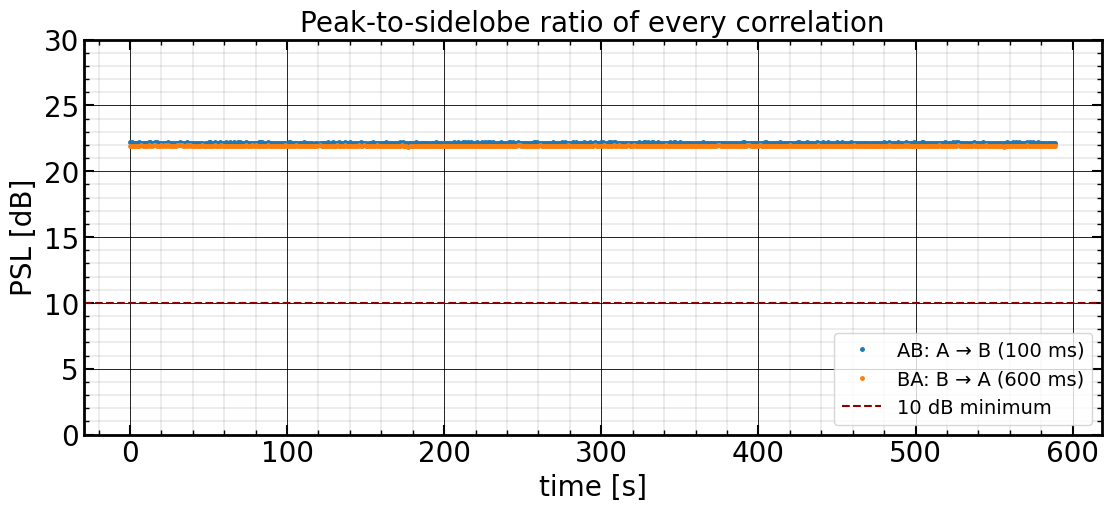

In [6]:
print(f"paired seconds: {len(resA)} (A ran {len(locA)} s, B {len(locB)} s; B started 3 s after A)")
for name, loc in (("A", locA), ("B", locB)):
    cs = sorted(l["count"] for l in loc)
    gaps = sorted(set(range(cs[0], cs[-1] + 1)) - set(cs))
    print(f"node {name}: PPS counts {cs[0]}-{cs[-1]}, skipped (no record, no TX/RX): {gaps if gaps else 'none'}")
print(f"valid: {np.isfinite(theta).sum()}, slot errors: "
      f"{sum('error' in l['slots'][s] for l in locA + locB for s in l['slots'])}")
for name, p, ph in (("AB (A -> B)", psl_ab, ph_ab), ("BA (B -> A)", psl_ba, ph_ba)):
    mph = np.angle(np.mean(np.exp(1j * ph)))                      # circular mean: the phase sits near ±π in one direction
    print(f"{name}: PSL min {p.min():.1f}, mean {p.mean():.1f} dB; carrier phase {mph:+.3f} rad, "
          f"sd {np.angle(np.exp(1j * (ph - mph))).std(ddof=1) * 1e3:.0f} mrad")
dieA = np.array([l["die_c"] for l in locA]); dieB = np.array([l["die_c"] for l in locB])
print(f"die temperature: A {dieA.min():.1f}-{dieA.max():.1f} C, B {dieB.min():.1f}-{dieB.max():.1f} C")

fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
ax.plot(t, psl_ab, ".", ms=5, color="tab:blue", label="AB: A → B (100 ms)")
ax.plot(t, psl_ba, ".", ms=5, color="tab:orange", label="BA: B → A (600 ms)")
ax.axhline(10, color="darkred", ls="--", lw=1.5, label="10 dB minimum")
ax.set_ylim(0, 30); ax.set_xlabel("time [s]"); ax.set_ylabel("PSL [dB]")
ax.set_title("Peak-to-sidelobe ratio of every correlation", fontsize=20)
ax.legend(fontsize=14, loc="lower right"); grids(ax)
fig.savefig(FIG / "psl.png", dpi=150); plt.show()

## 4. The two one-way measurements

Each direction as a deviation from its own mean. The directions are different hardware (AB: A's DAC, the AB cable, B's ADC; BA: B's DAC, the BA cable, A's ADC), so their means differ by the non-reciprocity.

m_AB: mean 291.9782 ns, sdev  1.69 ps, second-to-second 1.81 ps, trend +0.01 ps/min, range 10.6 ps
m_BA: mean 292.0799 ns, sdev  1.46 ps, second-to-second 1.54 ps, trend +0.08 ps/min, range 8.5 ps
correlation between m_AB and m_BA of the same second: +0.17


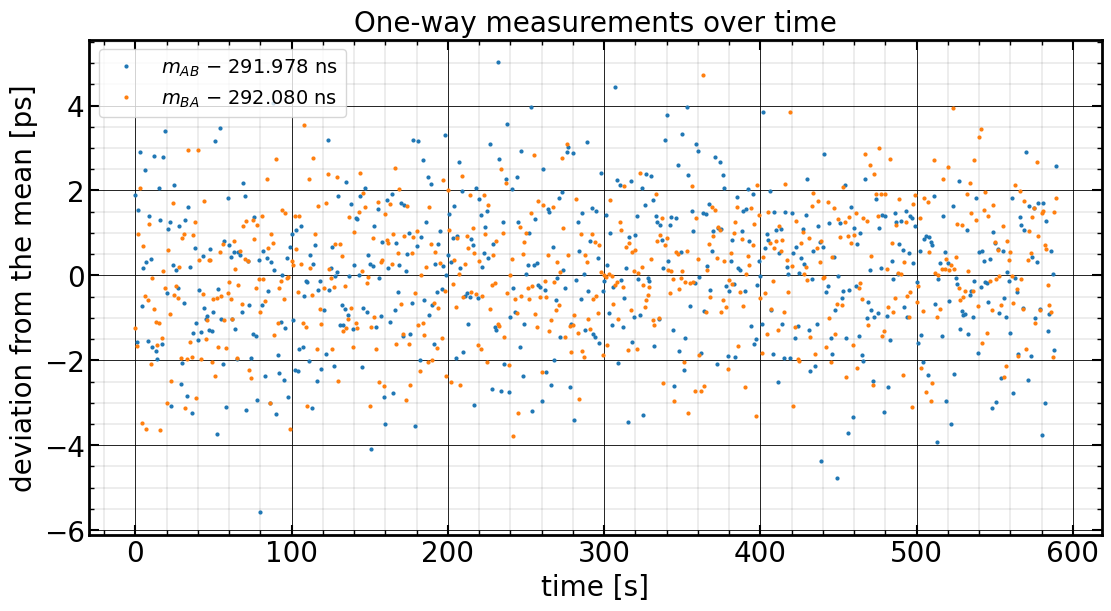

In [7]:
def trend(x):
    return np.polyfit(t, x, 1)[0] * 60
for name, m in (("m_AB", m_ab), ("m_BA", m_ba)):
    print(f"{name}: mean {m.mean():.4f} ns, sdev {m.std(ddof=1) * 1e3:5.2f} ps, "
          f"second-to-second {np.diff(m).std(ddof=1) / np.sqrt(2) * 1e3:4.2f} ps, "
          f"trend {trend(m) * 1e3:+.2f} ps/min, range {np.ptp(m) * 1e3:.1f} ps")
print(f"correlation between m_AB and m_BA of the same second: {np.corrcoef(m_ab, m_ba)[0, 1]:+.2f}")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (m_ab - m_ab.mean()) * 1e3, ".", ms=4, color="tab:blue", label=f"$m_{{AB}}$ − {m_ab.mean():.3f} ns")
ax.plot(t, (m_ba - m_ba.mean()) * 1e3, ".", ms=4, color="tab:orange", label=f"$m_{{BA}}$ − {m_ba.mean():.3f} ns")
ax.set_xlabel("time [s]"); ax.set_ylabel("deviation from the mean [ps]")
ax.set_title("One-way measurements over time", fontsize=20)
ax.legend(fontsize=14, loc="upper left"); grids(ax)
fig.savefig(FIG / "one_way.png", dpi=150); plt.show()

## 5. The clock offset θ

$\theta = (m_{AB} - m_{BA})/2$, the zero-baseline constant. Shown over time with a 30-s running mean, then per minute, then as a histogram.

theta: mean -0.05082 ns (-50.8 ps), sdev 1.02 ps, second-to-second 1.02 ps, range 6.1 ps


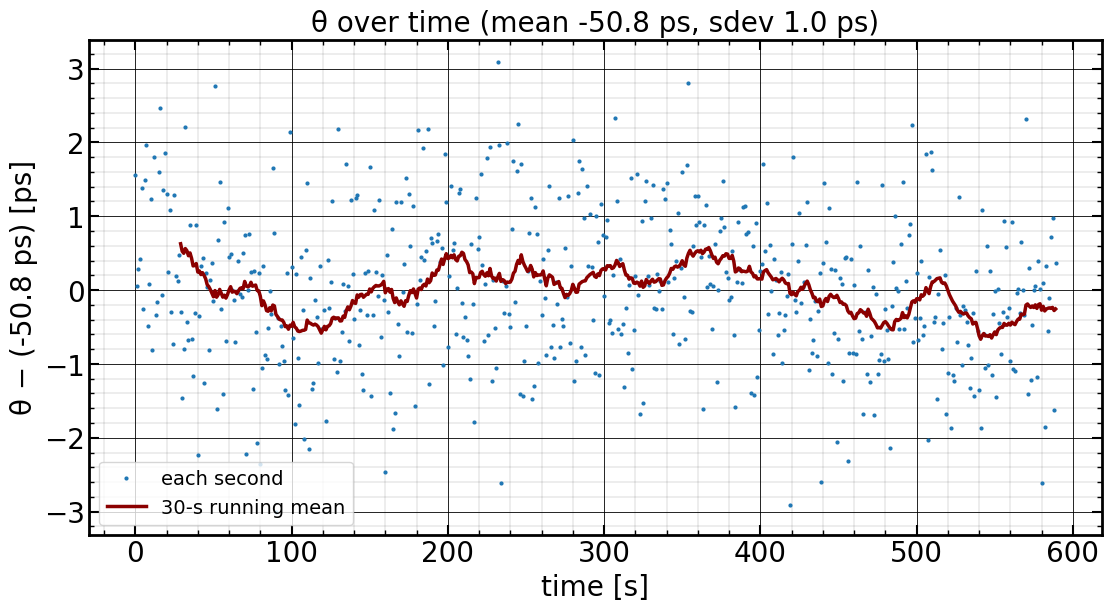

per minute:
    0- 60 s: theta   +0.28 ps (sdev 1.08), m_AB  -0.08, m_BA  -0.64 ps
   60-120 s: theta   -0.40 ps (sdev 1.01), m_AB  -0.73, m_BA  +0.07 ps
  120-180 s: theta   -0.05 ps (sdev 1.02), m_AB  -0.08, m_BA  +0.01 ps
  180-240 s: theta   +0.30 ps (sdev 1.11), m_AB  +0.46, m_BA  -0.14 ps
  240-300 s: theta   +0.20 ps (sdev 1.02), m_AB  +0.18, m_BA  -0.21 ps
  300-360 s: theta   +0.33 ps (sdev 0.94), m_AB  +0.58, m_BA  -0.07 ps
  360-420 s: theta   +0.09 ps (sdev 0.86), m_AB  +0.34, m_BA  +0.16 ps
  420-480 s: theta   -0.27 ps (sdev 0.93), m_AB  -0.31, m_BA  +0.24 ps
  480-540 s: theta   -0.25 ps (sdev 0.95), m_AB  -0.18, m_BA  +0.33 ps
  540-600 s: theta   -0.28 ps (sdev 0.91), m_AB  -0.24, m_BA  +0.33 ps


In [8]:
th_ps = theta * 1e3
th_mean, th_sd = th_ps.mean(), th_ps.std(ddof=1)
print(f"theta: mean {theta.mean():+.5f} ns ({th_mean:+.1f} ps), sdev {th_sd:.2f} ps, "
      f"second-to-second {np.diff(th_ps).std(ddof=1) / np.sqrt(2):.2f} ps, range {np.ptp(th_ps):.1f} ps")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, th_ps - th_mean, ".", ms=4, color="tab:blue", label="each second")
ax.plot(t[29:], np.convolve(th_ps - th_mean, np.ones(30) / 30, mode="valid"), "-", color="darkred", lw=2.5,
        label="30-s running mean")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"θ − ({th_mean:+.1f} ps) [ps]")
ax.set_title(f"θ over time (mean {th_mean:+.1f} ps, sdev {th_sd:.1f} ps)", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
fig.savefig(FIG / "theta_time.png", dpi=150); plt.show()

print("per minute:")
for k in range(0, len(th_ps), 60):
    s = slice(k, k + 60)
    print(f"  {k:3d}-{k + 60:3d} s: theta {th_ps[s].mean() - th_mean:+7.2f} ps (sdev {th_ps[s].std(ddof=1):4.2f}), "
          f"m_AB {(m_ab[s].mean() - m_ab.mean()) * 1e3:+6.2f}, m_BA {(m_ba[s].mean() - m_ba.mean()) * 1e3:+6.2f} ps")

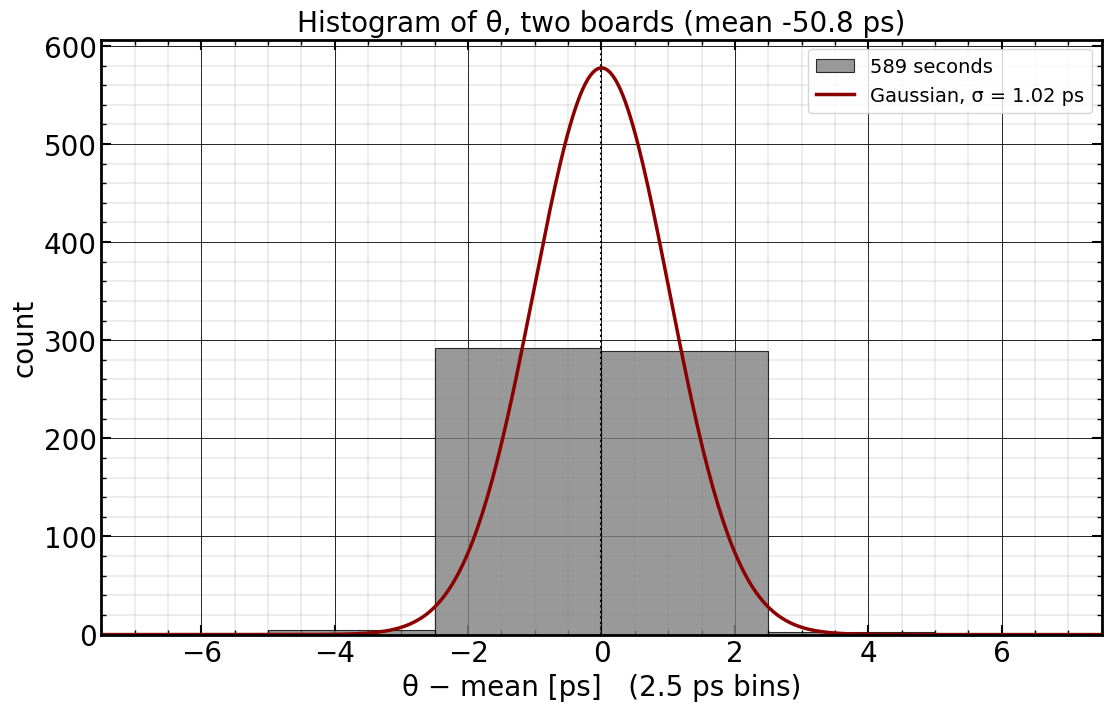

Shapiro-Wilk p = 0.57 (consistent with a Gaussian)


In [9]:
BIN_PS = 2.5
dev = th_ps - th_mean
edge = BIN_PS * np.ceil(np.abs(dev).max() / BIN_PS + 1)
bins = np.arange(-edge, edge + BIN_PS / 2, BIN_PS)
x = np.linspace(bins[0], bins[-1], 400)
fig, ax = plt.subplots(1, 1, figsize=(11, 7), layout='constrained')
ax.hist(dev, bins=bins, color="grey", edgecolor="k", lw=0.8, alpha=0.8, label=f"{dev.size} seconds")
ax.plot(x, dev.size * BIN_PS * stats.norm.pdf(x, 0, th_sd), "-", color="darkred", lw=2.5,
        label=f"Gaussian, σ = {th_sd:.2f} ps")
ax.axvline(0, color="k", ls=":", lw=1.5)
ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel(f"θ − mean [ps]   ({BIN_PS} ps bins)"); ax.set_ylabel("count")
ax.set_title(f"Histogram of θ, two boards (mean {th_mean:+.1f} ps)", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "theta_histogram.png", dpi=150); plt.show()
pv = stats.shapiro(dev).pvalue
print(f"Shapiro-Wilk p = {pv:.2g} ({'consistent with' if pv > 0.05 else 'not'} a Gaussian"
      f"{'' if pv > 0.05 else ': the B -> A step and drift (section 9) widen the distribution'})")

### Worked example: one value of θ from the raw data

This follows one second from the two boards' logs and the window B actually recorded to the logged θ, in four steps.

**Which second.** Each board counts its PPS from its own start (A started first, so A's count is higher; the offset is printed below), and the two boards' records are paired by their NTP time. Each board also saved the window it received every 60 s, at *its own* counts 6, 66, 126, … . Because of the count offset no paired second has both raw windows, so the example uses a second for which **B's raw window of the A → B burst is saved**. For B → A the example uses the peak that A logged for that second, and checks A's own saved window with the same count number (a few seconds earlier) to show the logged peaks come from the same calculation.

In [10]:
import importlib.util, sys
spec = importlib.util.spec_from_file_location(
    "correlator", "rf_clock_board/reference/rf_clock_v1.3.0.8/src/rf_clock/correlator.py")
correlator = importlib.util.module_from_spec(spec); sys.modules["correlator"] = correlator
spec.loader.exec_module(correlator)
ref = np.load("rf_clock_board/logs/m3_capture_20261027_232357.npz")["ref"]   # the transmitted PRN burst

def saved(rx_dir, slot):
    files = sorted(rx_dir.glob(f"{slot}_*.npy"), key=lambda p: int(p.stem.split("_")[1]))
    return [(int(f.stem.split("_")[1]), np.load(f).astype(np.complex128)) for f in files]

capAB = saved(DIR / f"rx_B_{RUN}", "AB"); capBA = saved(DIR / f"rx_A_{RUN}", "BA")

OFF = resA[0]["count_a"] - resA[0]["count_b"]          # A's count minus B's for the same second
paired_b = {r["count_b"] for r in resA}
cB = [c for c in sorted(dict(capAB)) if c in paired_b and c in dict(capBA)][1]   # a saved window of B that was paired
rE = next(r for r in resA if r["count_b"] == cB)
eA, eB = byA[rE["count_a"]], byB[rE["count_b"]]
print(f"A's count is {OFF} above B's. Paired second: A count {rE['count_a']}, B count {rE['count_b']}; "
      f"NTP times of the two records differ by {abs(eA['t_sys'] - eB['t_sys']) * 1e3:.0f} ms\n")
print("                      node A (AB)          node B (72A)")
print(f"PPS tick             {eA['pps_tick']:>14d}       {eB['pps_tick']:>14d}   (100 MHz ticks since each board started)")
print(f"slot AB  TX / window  A TX  PPS+{eA['slots']['AB']['tx'] - eA['pps_tick']:<10d}  B window PPS+{eB['slots']['AB']['rx']['tick'] - eB['pps_tick']}")
print(f"slot BA  window / TX  A window PPS+{eA['slots']['BA']['rx']['tick'] - eA['pps_tick']:<9d} B TX  PPS+{eB['slots']['BA']['tx'] - eB['pps_tick']}")

A's count is 10 above B's. Paired second: A count 76, B count 66; NTP times of the two records differ by 2 ms

                      node A (AB)          node B (72A)
PPS tick                 7554540918           6512589006   (100 MHz ticks since each board started)
slot AB  TX / window  A TX  PPS+10000000    B window PPS+9999875
slot BA  window / TX  A window PPS+59999875  B TX  PPS+60000000


**Step 1: when each burst is sent and when each window opens.** Every board measures time in its own 100 MHz ticks (10 ns), counted from the tick at which its own PPS arrived. In slot AB, A transmits at PPS + 10 000 000 ticks (100 ms) and B opens its receive window 125 ticks (1.25 µs) earlier by its own clock, so the burst falls inside the window. Slot BA is the same at PPS + 60 000 000 ticks, with B transmitting and A receiving. The large absolute tick numbers above cancel: only the positions relative to each board's own PPS enter.

**Step 2: where in the window the burst is (correlation).** The received window $r[n]$ (800 MS/s complex, 1.25 ns per sample) is cross-correlated with the transmitted burst $s[n]$:

$$c[k] = \sum_n r[n+k]\, s^*[n],$$

and the burst starts at the lag $k_0$ where $|c|$ peaks. The sample with the largest $|c|$ gives $k_0$ to 1.25 ns; a parabola through that sample and its two neighbours ($L$, $C$, $R$) refines it:

$$k_0 = k_{\max} + \frac{1}{2}\,\frac{L - R}{L - 2C + R}.$$

In [11]:
rx_ab = dict(capAB)[cB]                       # the window B recorded in slot AB of this second
c_ab = correlator.correlate(rx_ab, ref); mag = np.abs(c_ab)
k = int(np.argmax(mag)); L, C, R = mag[k - 1], mag[k], mag[k + 1]
k0 = k + 0.5 * (L - R) / (L - 2 * C + R)
print(f"window: {rx_ab.size} samples ({rx_ab.size * 1.25:.0f} ns); burst: {ref.size} samples")
print(f"largest |c| at k = {k}:  L = {L:.4g}, C = {C:.4g}, R = {R:.4g}")
print(f"k0 = {k} + 0.5 x ({L:.4g} - {R:.4g}) / ({L:.4g} - 2 x {C:.4g} + {R:.4g}) = {k0:.4f} samples")
print(f"logged by B for this second:  {eB['slots']['AB']['rx']['peak']:.4f} samples  "
      f"(PSL {correlator.find_peak(c_ab).peak_to_sidelobe_db:.1f} dB)")

window: 43848 samples (54810 ns); burst: 32841 samples
largest |c| at k = 1234:  L = 5.133e+10, C = 5.155e+10, R = 4.917e+10
k0 = 1234 + 0.5 x (5.133e+10 - 4.917e+10) / (5.133e+10 - 2 x 5.155e+10 + 4.917e+10) = 1233.5832 samples
logged by B for this second:  1233.5832 samples  (PSL 22.2 dB)


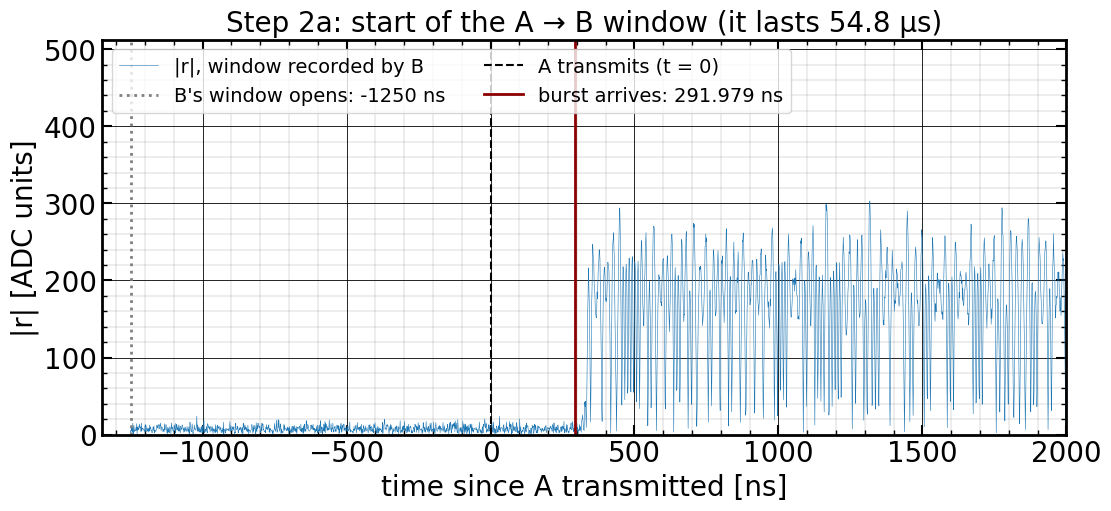

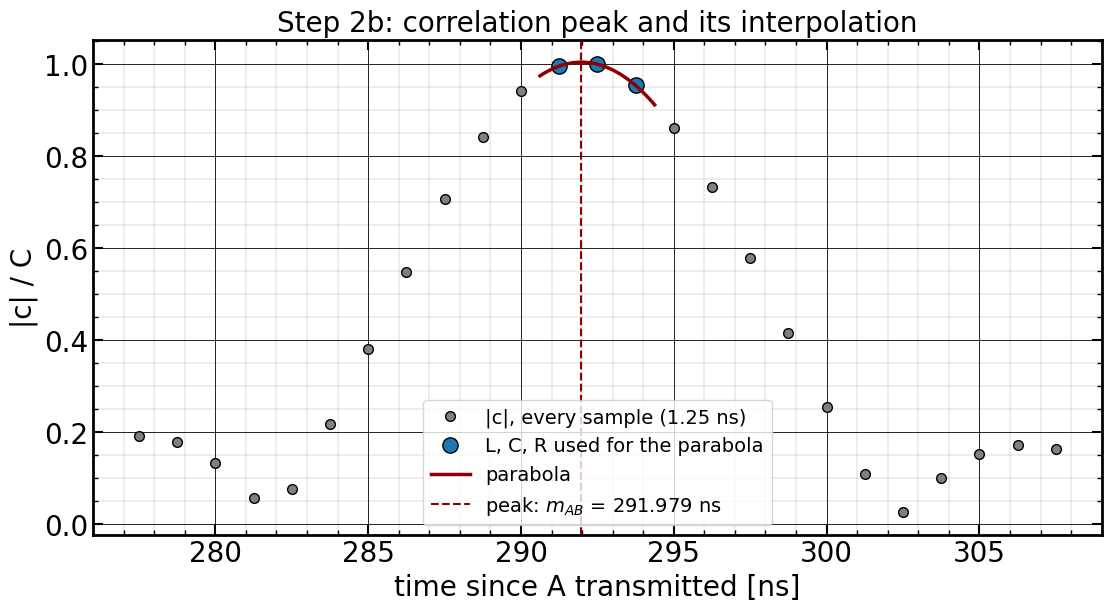

In [12]:
tx_ab = eA["slots"]["AB"]["tx"] - eA["pps_tick"]; win_ab = eB["slots"]["AB"]["rx"]["tick"] - eB["pps_tick"]
t_win = (win_ab - tx_ab) * 10.0                # window start, ns after A transmitted (by the two PPS)
tt = t_win + np.arange(rx_ab.size) * 1.25
fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
ax.plot(tt, np.abs(rx_ab), lw=0.4, color="tab:blue", label="|r|, window recorded by B")
ax.axvline(t_win, color="grey", ls=":", lw=2, label=f"B's window opens: {t_win:.0f} ns")
ax.axvline(0, color="k", ls="--", lw=1.5, label="A transmits (t = 0)")
ax.axvline(t_win + k0 * 1.25, color="darkred", lw=2, label=f"burst arrives: {t_win + k0 * 1.25:.3f} ns")
ax.set_xlim(t_win - 100, 2000); ax.set_ylim(0, 1.6 * np.abs(rx_ab).max())
ax.set_xlabel("time since A transmitted [ns]"); ax.set_ylabel("|r| [ADC units]")
ax.set_title(f"Step 2a: start of the A → B window (it lasts {rx_ab.size * 1.25 / 1e3:.1f} µs)", fontsize=20)
ax.legend(fontsize=14, loc="upper left", ncol=2); grids(ax)
fig.savefig(FIG / "example_window_AB.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
w = np.arange(k - 12, k + 13)
ax.plot(t_win + w * 1.25, mag[w] / C, "o", ms=7, color="grey", mec="k", label="|c|, every sample (1.25 ns)")
ax.plot(t_win + np.array([k - 1, k, k + 1]) * 1.25, np.array([L, C, R]) / C, "o", ms=11, color="tab:blue",
        mec="k", label="L, C, R used for the parabola")
xs = np.linspace(k - 1.5, k + 1.5, 200)
a2 = (L - 2 * C + R) / 2; a1 = (R - L) / 2
ax.plot(t_win + xs * 1.25, (C + a1 * (xs - k) + a2 * (xs - k) ** 2) / C, "-", color="darkred", lw=2.5, label="parabola")
ax.axvline(t_win + k0 * 1.25, color="darkred", ls="--", lw=1.5, label=f"peak: $m_{{AB}}$ = {t_win + k0 * 1.25:.3f} ns")
ax.set_xlabel("time since A transmitted [ns]"); ax.set_ylabel("|c| / C")
ax.set_title("Step 2b: correlation peak and its interpolation", fontsize=20)
ax.legend(fontsize=14, loc="lower center"); grids(ax)
fig.savefig(FIG / "example_peak_AB.png", dpi=150); plt.show()

**Step 3: the two one-way measurements.** The time from transmission to arrival, each end on its own clock:

$$m = \big[(\text{window tick} - \text{PPS}_{\text{receiver}}) - (\text{TX tick} - \text{PPS}_{\text{transmitter}})\big] \times 10\ \text{ns} + k_0 \times 1.25\ \text{ns}.$$

The first term is the window's start relative to the transmission (−125 ticks = −1250 ns); the second is how far into the window the burst arrived.

In [13]:
m_ab_e = t_win + k0 * 1.25
tx_ba = eB["slots"]["BA"]["tx"] - eB["pps_tick"]; win_ba = eA["slots"]["BA"]["rx"]["tick"] - eA["pps_tick"]
k0_ba = eA["slots"]["BA"]["rx"]["peak"]
m_ba_e = (win_ba - tx_ba) * 10.0 + k0_ba * 1.25
print(f"m_AB = ({win_ab} - {tx_ab}) x 10 ns + {k0:.4f} x 1.25 ns = {m_ab_e:.4f} ns   (logged {rE['m_ab_ns']:.4f} ns)")
print(f"m_BA = ({win_ba} - {tx_ba}) x 10 ns + {k0_ba:.4f} x 1.25 ns = {m_ba_e:.4f} ns   (logged {rE['m_ba_ns']:.4f} ns)")
pB = correlator.estimate_delay(dict(capBA)[cB], ref)
print(f"\ncheck of the BA peak calculation on A's own saved window (A count {cB}, {OFF} s earlier): "
      f"recomputed {pB.index:.4f}, logged {byA[cB]['slots']['BA']['rx']['peak']:.4f} samples")

m_AB = (9999875 - 10000000) x 10 ns + 1233.5832 x 1.25 ns = 291.9790 ns   (logged 291.9790 ns)
m_BA = (59999875 - 60000000) x 10 ns + 1233.6638 x 1.25 ns = 292.0797 ns   (logged 292.0797 ns)

check of the BA peak calculation on A's own saved window (A count 66, 10 s earlier): recomputed 1233.6635, logged 1233.6635 samples


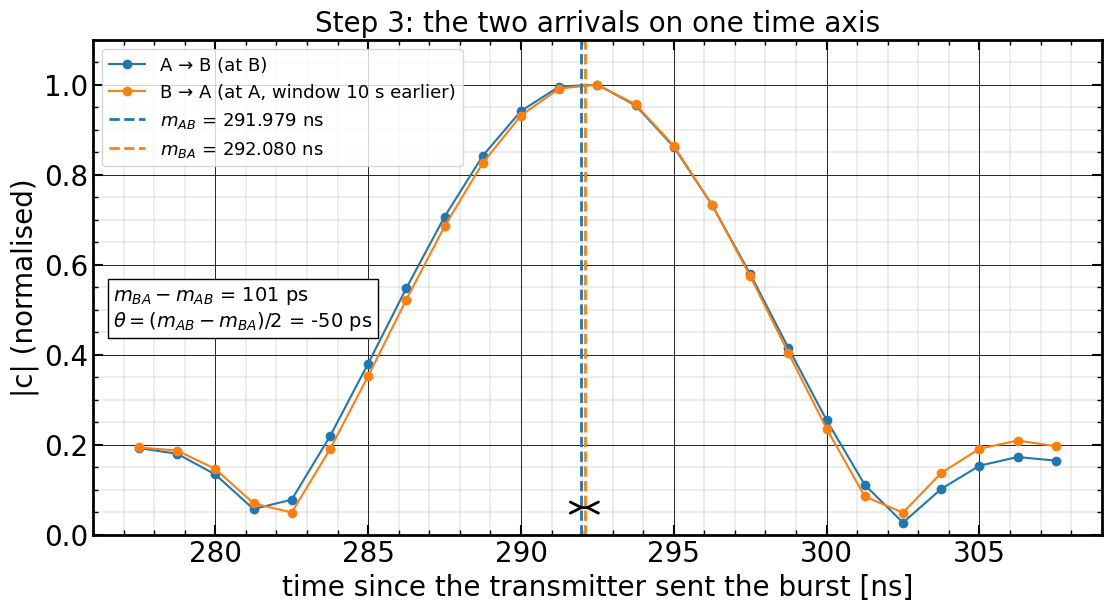

In [14]:
rx_ba = dict(capBA)[cB]; c_ba = np.abs(correlator.correlate(rx_ba, ref))
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
for lab, cm, t_w, kk, col in (("A → B (at B)", mag, t_win, k0, "tab:blue"),
                               (f"B → A (at A, window {OFF} s earlier)", c_ba, (win_ba - tx_ba) * 10.0, pB.index, "tab:orange")):
    j = int(round(kk)); w = np.arange(j - 12, j + 13)
    ax.plot(t_w + w * 1.25, cm[w] / cm[j], "o-", ms=6, lw=1.5, color=col, label=lab)
ax.axvline(m_ab_e, color="tab:blue", ls="--", lw=2, label=f"$m_{{AB}}$ = {m_ab_e:.3f} ns")
ax.axvline(m_ba_e, color="tab:orange", ls="--", lw=2, label=f"$m_{{BA}}$ = {m_ba_e:.3f} ns")
ax.annotate("", xy=(m_ba_e, 0.06), xytext=(m_ab_e, 0.06), arrowprops=dict(arrowstyle="<->", lw=2))
ax.text(0.02, 0.42, f"$m_{{BA}} - m_{{AB}}$ = {(m_ba_e - m_ab_e) * 1e3:.0f} ps\n$\\theta = (m_{{AB}} - m_{{BA}})/2$ = {(m_ab_e - m_ba_e) / 2 * 1e3:.0f} ps",
        ha="left", transform=ax.transAxes, fontsize=14, bbox=dict(facecolor="white", edgecolor="k"))
ax.set_xlabel("time since the transmitter sent the burst [ns]"); ax.set_ylabel("|c| (normalised)")
ax.set_ylim(0, 1.1)
ax.set_title("Step 3: the two arrivals on one time axis", fontsize=20)
ax.legend(fontsize=13, loc="upper left"); grids(ax)
fig.savefig(FIG / "example_two_arrivals.png", dpi=150); plt.show()

**Step 4: θ and the one-way delay.** Write $d_{AB}$, $d_{BA}$ for the true propagation times (cables, filters, attenuators and the converter paths of both boards) and $t_A$, $t_B$ for the true times of the two boards' PPS ticks. A's burst leaves at $t_A$ + 100 ms and arrives at $t_A$ + 100 ms + $d_{AB}$; B measures that arrival from $t_B$, so

$$m_{AB} = d_{AB} + (t_A - t_B), \qquad m_{BA} = d_{BA} - (t_A - t_B).$$

Half the difference and half the sum separate the clocks from the path:

$$\theta = \frac{m_{AB} - m_{BA}}{2} = (t_A - t_B) + \frac{d_{AB} - d_{BA}}{2}, \qquad \text{delay} = \frac{m_{AB} + m_{BA}}{2} = \frac{d_{AB} + d_{BA}}{2}.$$

A clock offset changes the two directions in opposite ways and moves θ one for one. A delay common to both directions (a longer shared cable, temperature) cancels in θ. A difference between the two directions, the non-reciprocity $\Delta = d_{AB} - d_{BA}$, enters θ as $\Delta/2$ and **cannot be told apart from a clock offset**. That is why a zero-baseline run like this one is needed: it measures the constant to subtract.

In [15]:
th_e = (m_ab_e - m_ba_e) / 2; dl_e = (m_ab_e + m_ba_e) / 2
print(f"theta = ({m_ab_e:.4f} - {m_ba_e:.4f}) / 2 = {th_e * 1e3:+.2f} ps   (logged {rE['theta_ns'] * 1e3:+.2f} ps; "
      f"run mean {th_mean:+.1f} ps)")
print(f"delay = ({m_ab_e:.4f} + {m_ba_e:.4f}) / 2 = {dl_e:.4f} ns   (logged {rE['delay_ns']:.4f} ns)\n")
print("What each kind of change would do to this second (illustration):")
print("                                            m_AB [ns]   m_BA [ns]   theta [ps]   delay [ns]")
for lab, dab, dba, off in (("as measured", 0, 0, 0),
                           ("B's clock 1 ns early (t_A - t_B = +1 ns)", 0, 0, 1),
                           ("both paths 1 ns longer", 1, 1, 0),
                           ("A->B path alone 1 ns longer (Delta)", 1, 0, 0)):
    a, b = m_ab_e + dab + off, m_ba_e + dba - off
    print(f"  {lab:42s} {a:10.4f}  {b:10.4f}   {(a - b) / 2 * 1e3:+9.2f}   {(a + b) / 2:9.4f}")

theta = (291.9790 - 292.0797) / 2 = -50.38 ps   (logged -50.38 ps; run mean -50.8 ps)
delay = (291.9790 + 292.0797) / 2 = 292.0293 ns   (logged 292.0293 ns)

What each kind of change would do to this second (illustration):
                                            m_AB [ns]   m_BA [ns]   theta [ps]   delay [ns]
  as measured                                  291.9790    292.0797      -50.38    292.0293
  B's clock 1 ns early (t_A - t_B = +1 ns)     292.9790    291.0797     +949.62    292.0293
  both paths 1 ns longer                       292.9790    293.0797      -50.38    293.0293
  A->B path alone 1 ns longer (Delta)          292.9790    292.0797     +449.62    292.5293


## 6. The one-way delay

$(m_{AB} + m_{BA})/2$: cables, filters, attenuators and both boards' converter paths.

one-way delay: mean 292.0291 ns, sdev 1.20 ps, trend +0.04 ps/min


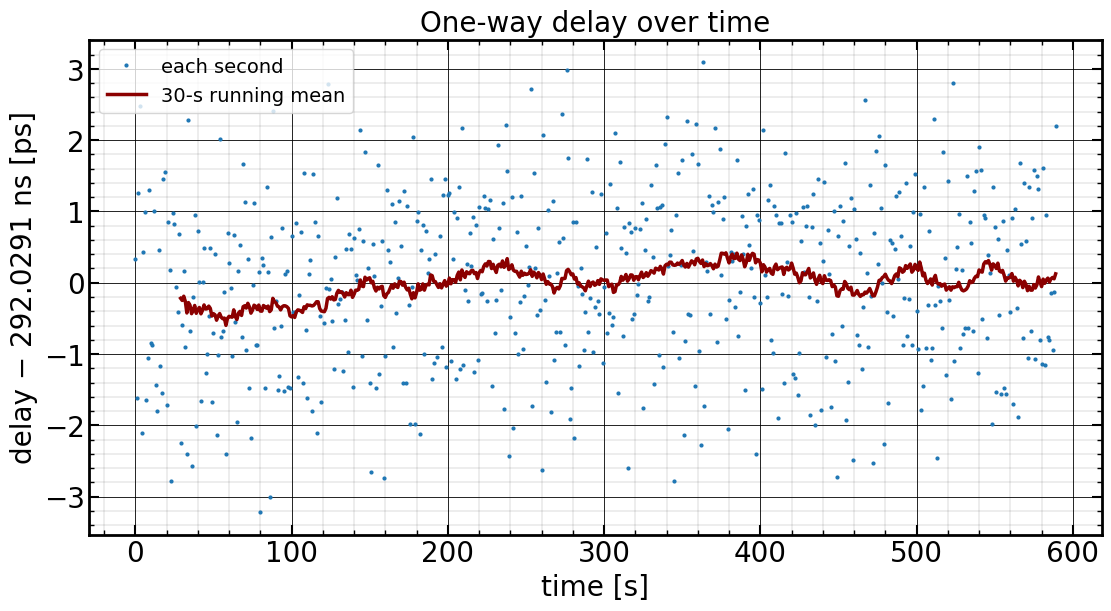

In [16]:
print(f"one-way delay: mean {delay.mean():.4f} ns, sdev {delay.std(ddof=1) * 1e3:.2f} ps, trend {trend(delay) * 1e3:+.2f} ps/min")
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (delay - delay.mean()) * 1e3, ".", ms=4, color="tab:blue", label="each second")
ax.plot(t[29:], np.convolve((delay - delay.mean()) * 1e3, np.ones(30) / 30, mode="valid"), "-", color="darkred",
        lw=2.5, label="30-s running mean")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"delay − {delay.mean():.4f} ns [ps]")
ax.set_title("One-way delay over time", fontsize=20)
ax.legend(fontsize=14, loc="upper left"); grids(ax)
fig.savefig(FIG / "delay_time.png", dpi=150); plt.show()

## 7. Stability with averaging

Standard deviation of the mean of N consecutive seconds, and the overlapping Allan deviation of θ (θ taken as the time error between the two boards; see the self-test notebook for the definition).

N =   1: theta  1.02   m_AB  1.69   m_BA  1.46 ps
N =   2: theta  0.70   m_AB  1.11   m_BA  0.96 ps
N =   5: theta  0.51   m_AB  0.73   m_BA  0.62 ps
N =  10: theta  0.41   m_AB  0.55   m_BA  0.46 ps
N =  20: theta  0.34   m_AB  0.47   m_BA  0.36 ps
N =  30: theta  0.34   m_AB  0.46   m_BA  0.36 ps
N =  60: theta  0.28   m_AB  0.41   m_BA  0.29 ps


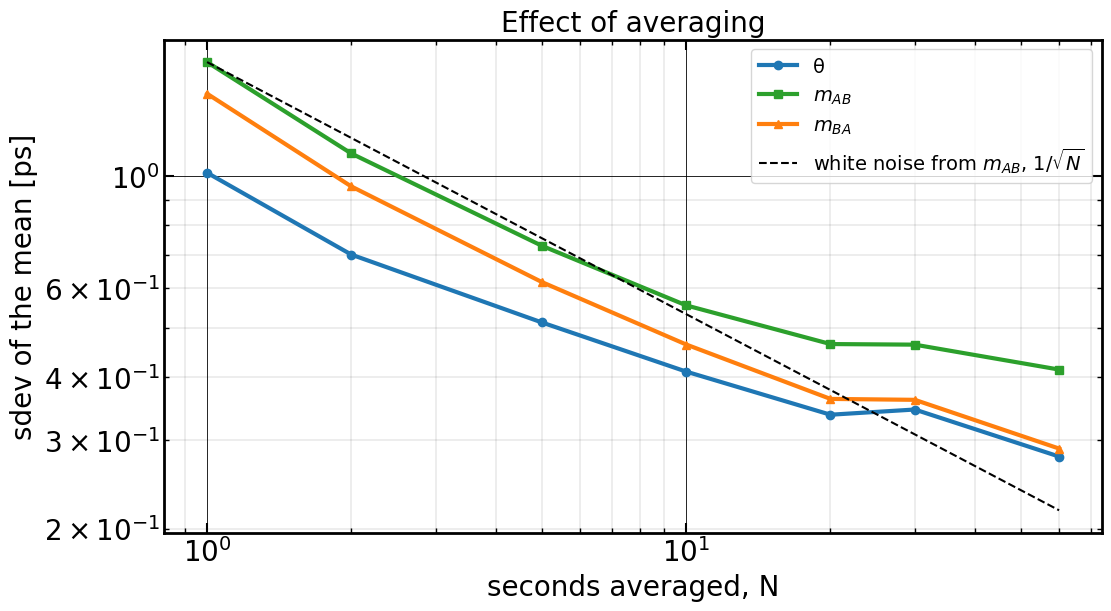

In [17]:
def sd_of_mean(y, Ns):
    out = []
    for n in Ns:
        k = y.size // n
        out.append(y[: k * n].reshape(k, n).mean(axis=1).std(ddof=1))
    return np.array(out)

def oadev(x_s, taus):
    return np.array([np.sqrt(np.mean((x_s[2 * m:] - 2 * x_s[m:-m] + x_s[:-2 * m]) ** 2) / (2 * m ** 2)) for m in taus])

Ns = np.array([1, 2, 5, 10, 20, 30, 60])
sd_th, sd_ab, sd_ba = sd_of_mean(th_ps, Ns), sd_of_mean(m_ab * 1e3, Ns), sd_of_mean(m_ba * 1e3, Ns)
for n, a, b, c in zip(Ns, sd_th, sd_ab, sd_ba):
    print(f"N = {n:3d}: theta {a:5.2f}   m_AB {b:5.2f}   m_BA {c:5.2f} ps")
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(Ns, sd_th, "o-", color="tab:blue", label="θ")
ax.loglog(Ns, sd_ab, "s-", color="tab:green", label="$m_{AB}$")
ax.loglog(Ns, sd_ba, "^-", color="tab:orange", label="$m_{BA}$")
ax.loglog(Ns, sd_ab[0] / np.sqrt(Ns), "k--", lw=1.5, label="white noise from $m_{AB}$, $1/\\sqrt{N}$")
ax.set_xlabel("seconds averaged, N"); ax.set_ylabel("sdev of the mean [ps]")
ax.set_title("Effect of averaging", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "averaging.png", dpi=150); plt.show()

tau =   1 s: ADEV 1.77e-12
tau =   2 s: ADEV 9.06e-13
tau =   3 s: ADEV 5.04e-13
tau =   4 s: ADEV 4.25e-13
tau =   7 s: ADEV 2.51e-13
tau =  11 s: ADEV 1.51e-13
tau =  18 s: ADEV 9.31e-14
tau =  29 s: ADEV 6.26e-14
tau =  46 s: ADEV 3.53e-14
tau =  75 s: ADEV 2.31e-14
tau = 121 s: ADEV 1.35e-14
tau = 196 s: ADEV 9.51e-15


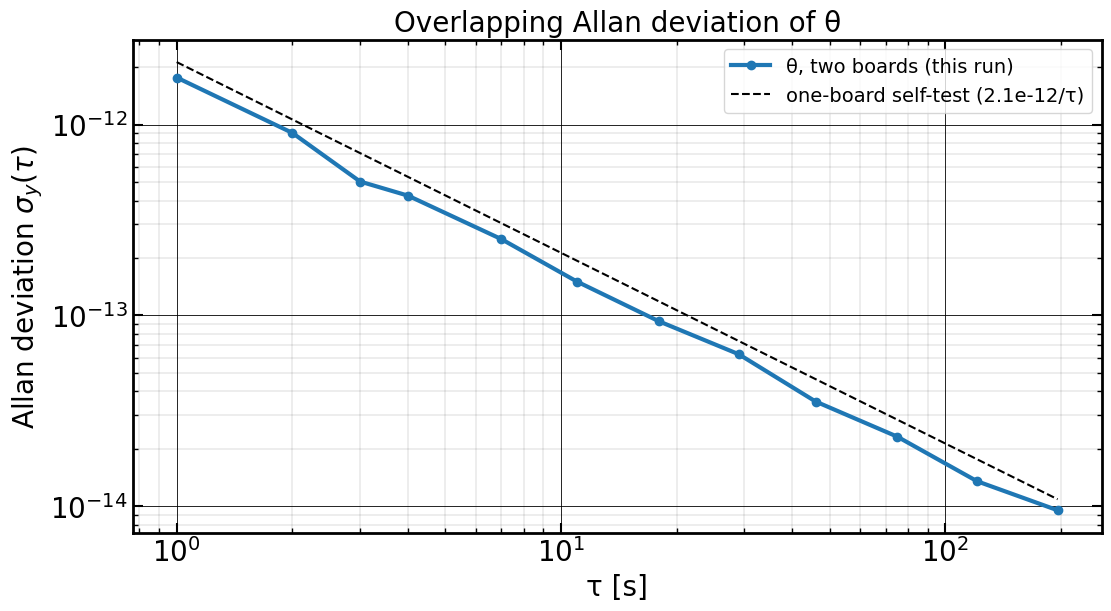

In [18]:
taus = np.unique(np.round(np.logspace(0, np.log10(th_ps.size // 3), 12)).astype(int))
ad = oadev(th_ps * 1e-12, taus)
for tau, v in zip(taus, ad):
    print(f"tau = {tau:3d} s: ADEV {v:.2e}")
ad_self = 2.13e-12 / taus                    # one-board self-test: 2.13e-12 at 1 s, falling as 1/tau
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(taus, ad, "o-", color="tab:blue", label="θ, two boards (this run)")
ax.loglog(taus, ad_self, "k--", lw=1.5, label="one-board self-test (2.1e-12/τ)")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("Overlapping Allan deviation of θ", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "allan.png", dpi=150); plt.show()

## 8. The saved captures: received levels of the two directions

Every 60 s each board kept the window it received (A: slot BA, B: slot AB), at its own counts (A's count is 7 above B's for the same second). The PRN reference is the same waveform and amplitude as in M3 (taken from the M3 capture file), and the correlator is the RF-clock source in this repository.

In [19]:
# correlator, reference burst and saved windows loaded in section 5 (worked example)
print("count  AB (A->B at B): rms   peak   PSL  |  BA (B->A at A): rms   peak   PSL")
for (ca, xa), (cb, xb) in zip(capAB, capBA):
    pa, pb = correlator.estimate_delay(xa, ref), correlator.estimate_delay(xb, ref)
    print(f"{ca:4d}/{cb:<4d}        {np.sqrt(np.mean(np.abs(xa) ** 2)):6.1f} {pa.index:8.3f} {pa.peak_to_sidelobe_db:5.1f}  |"
          f"        {np.sqrt(np.mean(np.abs(xb) ** 2)):6.1f} {pb.index:8.3f} {pb.peak_to_sidelobe_db:5.1f}")
def level(caps):            # median rms of the saved windows that contain the burst (PSL > 10 dB)
    return np.median([np.sqrt(np.mean(np.abs(x) ** 2)) for _, x in caps
                      if correlator.estimate_delay(x, ref).peak_to_sidelobe_db > 10])
lvl_ab, lvl_ba = level(capAB), level(capBA)
print(f"\nreceived level: AB {lvl_ab:.0f}, BA {lvl_ba:.0f} ADC units rms; BA relative to AB {20 * np.log10(lvl_ba / lvl_ab):+.1f} dB "
      f"(windows without a burst, PSL < 10 dB, left out)")

count  AB (A->B at B): rms   peak   PSL  |  BA (B->A at A): rms   peak   PSL
   6/6            154.2 1233.584  22.2  |           8.5 2532.452   0.3
  66/66           154.2 1233.583  22.2  |         175.7 1233.663  21.9
 126/126            8.5 6471.248   0.2  |         175.6 1233.661  21.9
 186/187          154.0 1233.583  22.1  |         175.6 1233.663  21.9
 246/247          154.0 1233.582  22.2  |         175.9 1233.665  22.0
 306/307          154.0 1233.582  22.2  |         175.8 1233.663  21.9
 366/367          153.9 1233.585  22.2  |         175.9 1233.662  21.9
 426/427          153.9 1233.584  22.2  |         176.0 1233.663  21.9
 486/487          153.7 1233.584  22.2  |         175.9 1233.664  21.9
 546/547          153.7 1233.583  22.1  |         176.0 1233.664  21.9



received level: AB 154, BA 176 ADC units rms; BA relative to AB +1.2 dB (windows without a burst, PSL < 10 dB, left out)


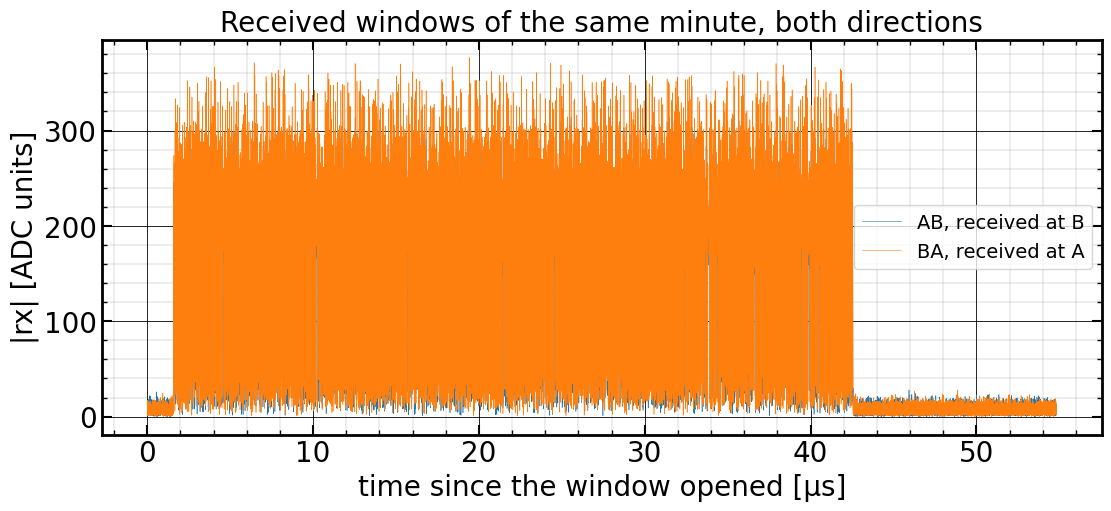

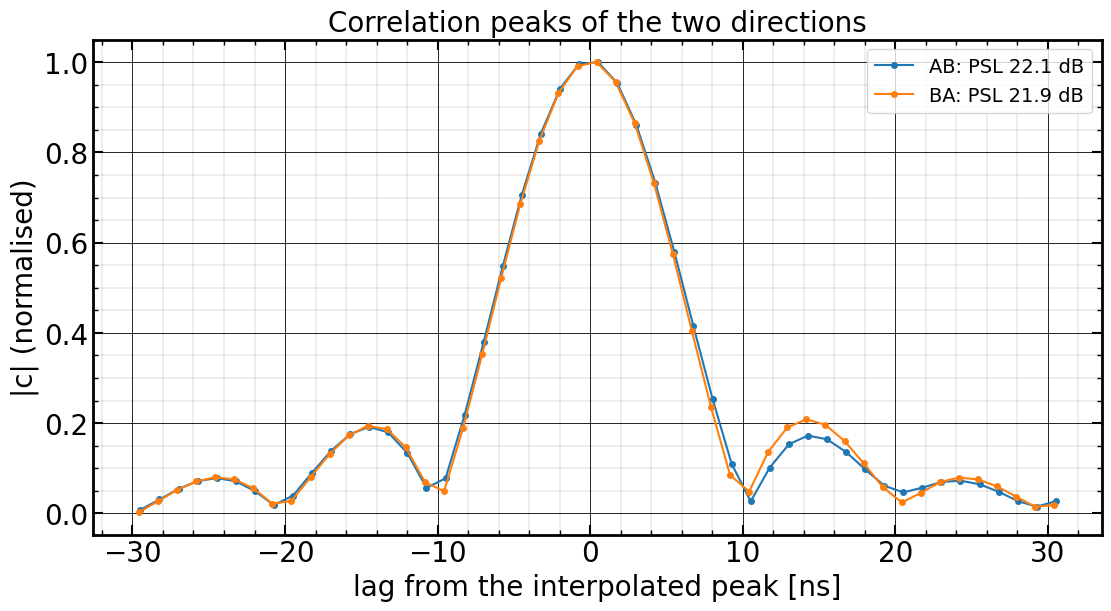

In [20]:
(_, xa), (_, xb) = capAB[3], capBA[3]
fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
tt = np.arange(xa.size) / 800e6 * 1e6
ax.plot(tt, np.abs(xa), lw=0.4, color="tab:blue", label="AB, received at B")
ax.plot(tt, np.abs(xb), lw=0.4, color="tab:orange", label="BA, received at A")
ax.set_xlabel("time since the window opened [µs]"); ax.set_ylabel("|rx| [ADC units]")
ax.set_title("Received windows of the same minute, both directions", fontsize=20)
ax.legend(fontsize=14, loc="center right"); grids(ax)
fig.savefig(FIG / "captures.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
for (lab, x, col) in (("AB", xa, "tab:blue"), ("BA", xb, "tab:orange")):
    c = np.abs(correlator.correlate(x, ref)); p = correlator.find_peak(correlator.correlate(x, ref))
    k = p.integer_index; w = np.arange(k - 24, k + 25)
    ax.plot((w - p.index) * 1.25, c[w] / c[k], "o-", ms=4, lw=1.5, color=col, label=f"{lab}: PSL {p.peak_to_sidelobe_db:.1f} dB")
ax.set_xlabel("lag from the interpolated peak [ns]"); ax.set_ylabel("|c| (normalised)")
ax.set_title("Correlation peaks of the two directions", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "correlation_peaks.png", dpi=150); plt.show()

## 9. Repeatability and the history of the two-board runs

All two-board runs of 27–28 October with the same boards, software and references, analysed the same way. Received levels come from each run's saved windows, per-second noise from the second-to-second differences. `20261028_123745` is the run just before this one with the same, fixed, set-up: the two together show whether the constant repeats after a restart of both boards.

In [21]:
s2s = lambda y: np.diff(y).std(ddof=1) / np.sqrt(2)
def resid(y, w=61):
    return y[w // 2: -(w // 2)] - np.convolve(y, np.ones(w) / w, mode="valid")
def load_run(run):
    d = Path("rf_clock_board/twtt_pair") / run
    rs = [l for l in read(d / f"twtt_A_{run}.jsonl") if l["type"] == "result"]
    ab = np.array([r["m_ab_ns"] for r in rs]); ba = np.array([r["m_ba_ns"] for r in rs])
    return dict(t=np.array([r["t_sys"] - rs[0]["t_sys"] for r in rs]), m_ab=ab, m_ba=ba, th=(ab - ba) / 2 * 1e3,
                lvl_ab=level(saved(d / f"rx_B_{run}", "AB")), lvl_ba=level(saved(d / f"rx_A_{run}", "BA")))
history = [("20261028_001010", "10 dB / 20 dB"), ("20261028_114317", "5 / 5 dB, loose connector"),
           ("20261028_123745", "5 / 5 dB, reseated"), (RUN, "5 / 5 dB, reseated (this run)")]
runs = {r: load_run(r) for r, _ in history}
print(f"{'run':16s} {'set-up':28s} {'BA-AB [dB]':>10s} {'m_AB s2s':>9s} {'m_BA s2s':>9s} {'m_BA range':>10s} "
      f"{'theta [ps]':>10s} {'sdev':>6s} {'s2s':>5s} {'ADEV 1 s':>9s} {'delay [ns]':>11s}")
for r, lab in history:
    x = runs[r]
    print(f"{r:16s} {lab:28s} {20 * np.log10(x['lvl_ba'] / x['lvl_ab']):+10.1f} {s2s(x['m_ab']) * 1e3:9.2f} "
          f"{s2s(x['m_ba']) * 1e3:9.2f} {np.ptp(x['m_ba']) * 1e3:10.1f} {x['th'].mean():+10.1f} {x['th'].std(ddof=1):6.2f} "
          f"{s2s(x['th']):5.2f} {oadev(x['th'] * 1e-12, [1])[0]:9.1e} {(x['m_ab'] + x['m_ba']).mean() / 2:11.4f}")

PREV = "20261028_123745"; P = runs[PREV]
tP, th_p = P["t"], P["th"]
tausP = np.unique(np.round(np.logspace(0, np.log10(th_p.size // 3), 12)).astype(int))
adP = oadev(th_p * 1e-12, tausP)
se = lambda y: y.std(ddof=1) / np.sqrt(y.size)
print(f"\nrepeatability of the constant: {PREV} {th_p.mean():+.2f} ± {se(th_p):.2f} ps, this run {th_mean:+.2f} ± {se(th_ps):.2f} ps "
      f"(mean ± standard error): difference {th_mean - th_p.mean():+.2f} ps")
print(f"one-way delay: {(P['m_ab'] + P['m_ba']).mean() / 2:.4f} ns and {delay.mean():.4f} ns: difference {(delay.mean() - (P['m_ab'] + P['m_ba']).mean() / 2) * 1e3:+.2f} ps")

run              set-up                       BA-AB [dB]  m_AB s2s  m_BA s2s m_BA range theta [ps]   sdev   s2s  ADEV 1 s  delay [ns]
20261028_001010  10 dB / 20 dB                     -10.9      1.93      5.79       74.8     -647.2   8.00  3.09   5.3e-12    292.5543
20261028_114317  5 / 5 dB, loose connector          -3.7      1.47      2.26       68.2     -571.3  12.26  1.42   2.4e-12    292.5159
20261028_123745  5 / 5 dB, reseated                 +1.1      1.72      1.69        8.9      -50.7   1.02  1.11   2.0e-12    292.0299
20261028_124958  5 / 5 dB, reseated (this run)       +1.2      1.81      1.54        8.5      -50.8   1.02  1.02   1.8e-12    292.0291

repeatability of the constant: 20261028_123745 -50.66 ± 0.04 ps, this run -50.82 ± 0.04 ps (mean ± standard error): difference -0.16 ps
one-way delay: 292.0299 ns and 292.0291 ns: difference -0.86 ps


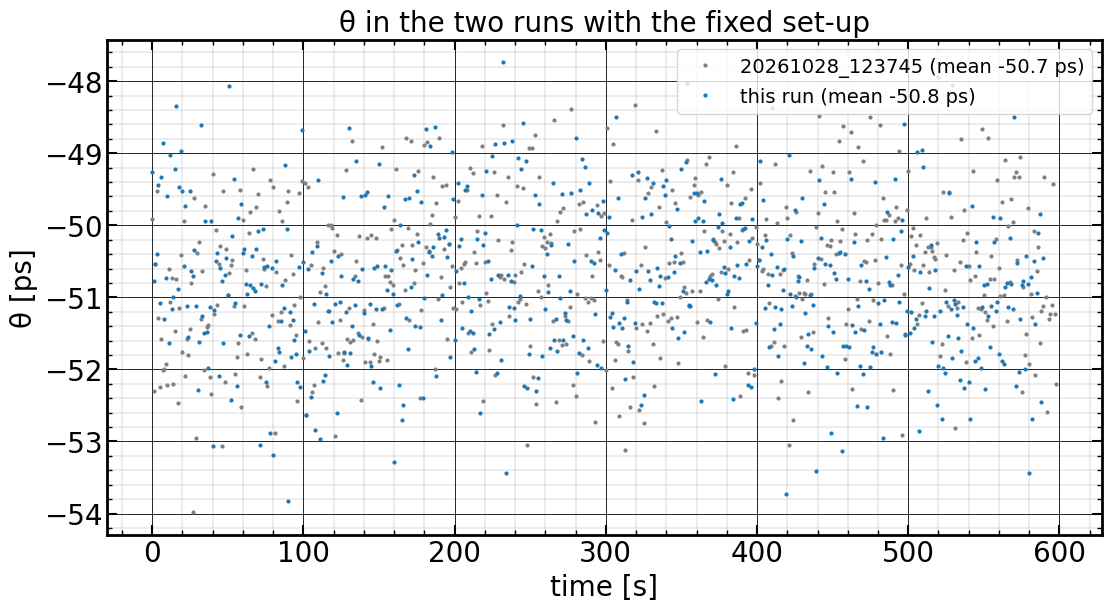

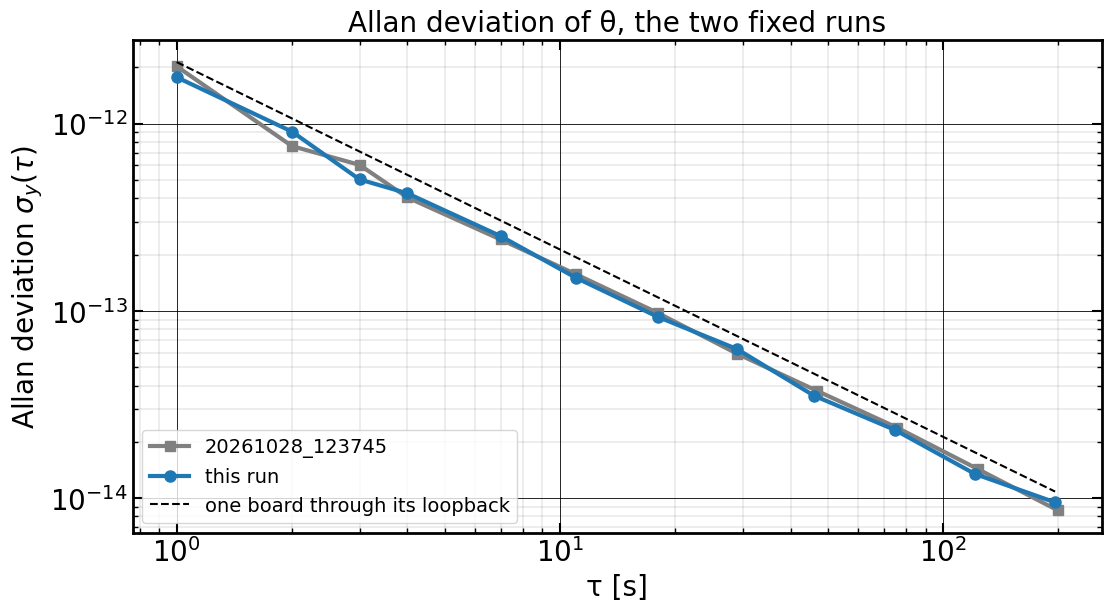

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(tP, th_p, ".", ms=4, color="grey", label=f"{PREV} (mean {th_p.mean():+.1f} ps)")
ax.plot(t, th_ps, ".", ms=4, color="tab:blue", label=f"this run (mean {th_mean:+.1f} ps)")
ax.set_xlabel("time [s]"); ax.set_ylabel("θ [ps]")
ax.set_title("θ in the two runs with the fixed set-up", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "repeat_theta.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(tausP, adP, "s-", color="grey", ms=7, label=PREV)
ax.loglog(taus, ad, "o-", color="tab:blue", ms=8, label="this run")
ax.loglog(taus, 2.13e-12 / taus, "k--", lw=1.5, label="one board through its loopback")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("Allan deviation of θ, the two fixed runs", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
fig.savefig(FIG / "repeat_allan.png", dpi=150); plt.show()

## 10. Comparison with the one-board self-test

In [23]:
rows = [
    ("One board (AB), loopback, 27 Oct, 300 s", "0 (truth)", "+0.06", "1.18", "2.1e-12"),
    ("Two boards, fixed set-up, 123745, 600 s", "0 (one FS725)", f"{th_p.mean():+.1f}", f"{th_p.std(ddof=1):.2f}", f"{adP[0]:.1e}"),
    ("Two boards, fixed set-up, this run, 600 s", "0 (one FS725)", f"{th_mean:+.1f}", f"{th_sd:.2f}", f"{ad[0]:.1e}"),
    ("  same, second-to-second only", "", "", f"{np.diff(th_ps).std(ddof=1) / np.sqrt(2):.2f}", ""),
]
print(f"{'':48s} {'true θ':>14s} {'θ mean [ps]':>12s} {'sdev [ps]':>10s} {'ADEV 1 s':>9s}")
for r in rows:
    print(f"{r[0]:48s} {r[1]:>14s} {r[2]:>12s} {r[3]:>10s} {r[4]:>9s}")

                                                         true θ  θ mean [ps]  sdev [ps]  ADEV 1 s
One board (AB), loopback, 27 Oct, 300 s               0 (truth)        +0.06       1.18   2.1e-12
Two boards, fixed set-up, 123745, 600 s           0 (one FS725)        -50.7       1.02   2.0e-12
Two boards, fixed set-up, this run, 600 s         0 (one FS725)        -50.8       1.02   1.8e-12
  same, second-to-second only                                                      1.02          


## 11. Summary

**With the B → A path fixed, the two-board link performs at the level of one board through its own loopback, and its constant repeats after a restart.**

* **Completeness:** 589 paired seconds, all valid, no slot errors, PSL ≥ 21.9 dB in both directions, both boards computed identical results, and the hand-worked second and the worked example from the raw window match the logs exactly. Node A skipped one second of its own (no record, no burst; its software loop missed that PPS), so B's window of that second is empty; this is the only gap.
* **Signal:** the two directions now arrive within 1.2 dB of each other (154 and 176 ADC units rms), and each received level is constant to 0.1 dB over the 10 minutes.
* **θ (zero-baseline constant) = −50.8 ps**, standard deviation **1.02 ps over the whole run** (range 6 ps, 1-minute means within ±0.4 ps), Gaussian (Shapiro–Wilk p = 0.57). Both one-way measurements are flat (1.7 and 1.5 ps, trends below 0.1 ps/min).
* **Allan deviation 1.8e-12 at 1 s, falling as 1/τ to 9.5e-15 at 196 s:** white time noise over the whole run, slightly below the one-board self-test (2.1e-12 at 1 s), because both received signals are now stronger than in that loopback (5 dB instead of 10 dB of attenuation).
* **Repeatability:** the run before this one, with the same set-up and both boards restarted in between (overlay, clocks, MTS), gave −50.66 ± 0.04 ps; this run −50.82 ± 0.04 ps (mean ± standard error). The constant repeats to **0.16 ps**, the one-way delay to 0.9 ps.

**How the set-up got here** (section 9): the first run (−647.2 ps, 8.0 ps, steps) had a 20 dB attenuator against 10 dB; matching them (5 dB both) fixed the level and the short-term noise (1.42 ps per second) but not the steps; reseating a loose connector in the B → A path removed the steps and the level drops and shortened B → A by about 1 ns, which is why the constant moved from about −571 ps to −50.7 ps. The constants of the earlier runs belong to faulty set-ups and should not be used.

**What −50.8 ps is:** half the non-reciprocity of the two directions plus the difference of the two boards' PPS-to-tick timing (EPG1 outputs 1 and 2, their cables). It is the calibration value of this set-up: a later measurement with this wiring subtracts it.

**Next:**
1. If time allows, one more repeat after a full power cycle of both boards (the restarts here reload the overlay but do not cut power).
2. The separate-reference test: each board on its own FS725 (10 MHz and PPS from the same unit, PPS outputs aligned to within about 1 µs). θ minus −50.8 ps then measures the real offset of the two references, to be compared with their PPS offset measured directly on the scope. Any change to the RF paths or the PPS cabling changes the constant, so it has to be measured again with the final wiring on one reference first.

Files: logs, console output and saved windows in `rf_clock_board/twtt_pair/20261028_124958/`, figures in its `figures/` folder; the earlier runs in the neighbouring `twtt_pair/` folders.


## 12. Report-ready results

What I would put in a report of this test: one table with the set-up and the key numbers, and five figures, each with a caption. The table is generated from the data above, the figures are saved as PNG and PDF (vector) in `figures/report_*`, and the numbers also go to `figures/report_summary.json`.

**Choice of figures**

| | Figure | Why it is in the report |
|---|---|---|
| R1 | θ over time, per second and per minute | the result itself: the constant and its scatter |
| R2 | the two one-way measurements | both directions behave alike |
| R3 | short-term θ noise histogram | the precision of a single 1-second measurement: the number to compare with other systems |
| R4 | Allan deviation of θ against the one-board self-test and the other fixed run | standard way to report time-transfer stability; puts this run in context |
| R5 | θ in the two fixed runs | the constant repeats after a restart |

In [24]:
from IPython.display import Markdown, display

res_win = 61                                   # centred running mean used to separate short-term noise from the steps
kern = np.ones(res_win) / res_win
th_slow = np.convolve(th_ps, kern, mode="valid")
th_res = th_ps[res_win // 2: -(res_win // 2)] - th_slow
minute = [(k, th_ps[k:k + 60].mean() - th_mean) for k in range(0, th_ps.size - 30, 60)]

key = {
    "run": RUN, "duration_s_per_board": 600, "paired_seconds": int(theta.size),
    "valid_seconds": int(np.isfinite(theta).sum()),
    "theta_mean_ps": round(th_mean, 1), "theta_sdev_ps": round(th_sd, 2),
    "theta_second_to_second_ps": round(float(np.diff(th_ps).std(ddof=1) / np.sqrt(2)), 2),
    "theta_short_term_residual_sdev_ps": round(float(th_res.std(ddof=1)), 2),
    "theta_minute_means_range_ps": round(float(np.ptp([m for _, m in minute])), 1),
    "adev_1s": float(f"{ad[0]:.2e}"), "adev_at_tau": {int(a): float(f"{b:.2e}") for a, b in zip(taus, ad)},
    "one_way_delay_ns": round(float(delay.mean()), 4),
    "m_ab_ns": round(float(m_ab.mean()), 4), "m_ab_sdev_ps": round(float(m_ab.std(ddof=1) * 1e3), 2),
    "m_ba_ns": round(float(m_ba.mean()), 4), "m_ba_sdev_ps": round(float(m_ba.std(ddof=1) * 1e3), 2),
    "psl_min_db": round(float(min(psl_ab.min(), psl_ba.min())), 1),
    "ba_level_relative_to_ab_db": round(float(20 * np.log10(lvl_ba / lvl_ab)), 1),
    "attenuators_db": {"AB": 5, "BA": 5}, "repeat_of": PREV, "repeat_theta_mean_ps": round(float(th_p.mean()), 2),
}
(FIG / "report_summary.json").write_text(json.dumps(key, indent=2) + "\n")

display(Markdown(f"""
**Table R1. Two-way time transfer between two RFSoC 4x2 boards, zero baseline (one FS725)**

| Set-up | |
|---|---|
| Boards | 8873292600AB (node A), 887329260072A (node B), RF-clock 1.3.0.10 |
| Signal | 4096-chip PRN, BPSK at 100 Mchip/s, RRC β = 0.25, 5.8 GHz carrier, 41 µs bursts |
| Exchange | one burst each way per second: A → B at PPS + 100 ms, B → A at PPS + 600 ms |
| Sampling | DAC 9.6 GS/s, ADC 4.8 GS/s, correlation on the ARM at 800 MS/s complex (1.25 ns samples), parabolic peak interpolation |
| References | FS725 10 MHz → EPG1 → splitter → both boards; FS725 1PPS → EPG1 outputs 1 (A) and 2 (B) |
| RF paths | DAC_A → 5725–5875 MHz band-pass filter → 5 dB attenuator → ADC_B, one per direction |
| Duration | 600 s per board, {key['paired_seconds']} paired seconds, {key['valid_seconds']} valid |

| Result | Value |
|---|---|
| θ (zero-baseline constant, true offset 0) | **{th_mean:+.1f} ps** |
| θ standard deviation, whole run | {th_sd:.1f} ps |
| θ short-term noise (second to second) | **{key['theta_second_to_second_ps']:.1f} ps** |
| θ Allan deviation | **{ad[0]:.1e} at 1 s**, {ad[list(taus).index(min(taus, key=lambda x: abs(x - 100)))]:.1e} at {min(taus, key=lambda x: abs(x - 100))} s |
| Spread of the 1-minute means of θ | {key['theta_minute_means_range_ps']:.1f} ps |
| One-way delay | {delay.mean():.3f} ns |
| $m_{{AB}}$ / $m_{{BA}}$ | {m_ab.mean():.3f} ns (sdev {m_ab.std(ddof=1) * 1e3:.1f} ps) / {m_ba.mean():.3f} ns (sdev {m_ba.std(ddof=1) * 1e3:.1f} ps) |
| Correlation quality | PSL ≥ {key['psl_min_db']:.1f} dB in both directions; BA received {key['ba_level_relative_to_ab_db']:+.1f} dB relative to AB |
| Reference points | one board through its loopback: θ = +0.06 ps (truth 0), 1.18 ps, 2.1e-12 at 1 s; the same two boards in the run before (fixed set-up): θ {th_p.mean():+.1f} ps, {th_p.std(ddof=1):.2f} ps, {adP[0]:.1e} at 1 s |
"""))


**Table R1. Two-way time transfer between two RFSoC 4x2 boards, zero baseline (one FS725)**

| Set-up | |
|---|---|
| Boards | 8873292600AB (node A), 887329260072A (node B), RF-clock 1.3.0.10 |
| Signal | 4096-chip PRN, BPSK at 100 Mchip/s, RRC β = 0.25, 5.8 GHz carrier, 41 µs bursts |
| Exchange | one burst each way per second: A → B at PPS + 100 ms, B → A at PPS + 600 ms |
| Sampling | DAC 9.6 GS/s, ADC 4.8 GS/s, correlation on the ARM at 800 MS/s complex (1.25 ns samples), parabolic peak interpolation |
| References | FS725 10 MHz → EPG1 → splitter → both boards; FS725 1PPS → EPG1 outputs 1 (A) and 2 (B) |
| RF paths | DAC_A → 5725–5875 MHz band-pass filter → 5 dB attenuator → ADC_B, one per direction |
| Duration | 600 s per board, 589 paired seconds, 589 valid |

| Result | Value |
|---|---|
| θ (zero-baseline constant, true offset 0) | **-50.8 ps** |
| θ standard deviation, whole run | 1.0 ps |
| θ short-term noise (second to second) | **1.0 ps** |
| θ Allan deviation | **1.8e-12 at 1 s**, 1.4e-14 at 121 s |
| Spread of the 1-minute means of θ | 0.7 ps |
| One-way delay | 292.029 ns |
| $m_{AB}$ / $m_{BA}$ | 291.978 ns (sdev 1.7 ps) / 292.080 ns (sdev 1.5 ps) |
| Correlation quality | PSL ≥ 21.9 dB in both directions; BA received +1.2 dB relative to AB |
| Reference points | one board through its loopback: θ = +0.06 ps (truth 0), 1.18 ps, 2.1e-12 at 1 s; the same two boards in the run before (fixed set-up): θ -50.7 ps, 1.02 ps, 2.0e-12 at 1 s |


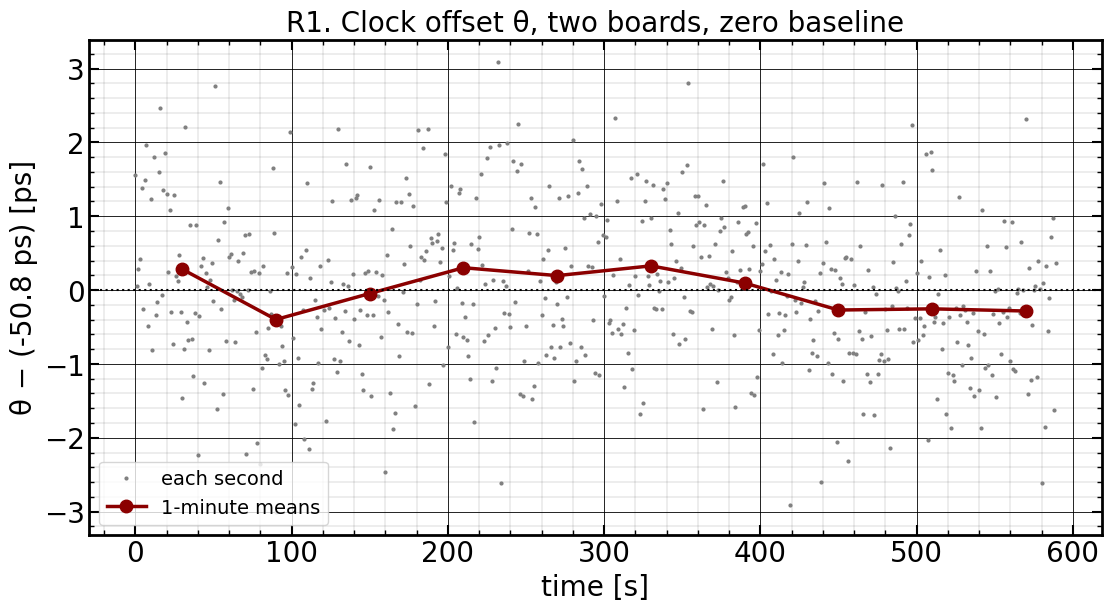

In [25]:
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200)
    fig.savefig(FIG / f"{name}.pdf")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, th_ps - th_mean, ".", ms=4, color="grey", label="each second")
mk = np.array([k + 30 for k, _ in minute]); mv = np.array([m for _, m in minute])
ax.plot(mk, mv, "o-", color="darkred", ms=9, lw=2.5, label="1-minute means")
ax.axhline(0, color="k", ls=":", lw=1.5)
ax.set_xlabel("time [s]"); ax.set_ylabel(f"θ − ({th_mean:+.1f} ps) [ps]")
ax.set_title("R1. Clock offset θ, two boards, zero baseline", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
save(fig, "report_R1_theta"); plt.show()

In [26]:
display(Markdown(f"**Figure R1.** Clock offset θ = (m_AB − m_BA)/2 between the two boards, both on one FS725 (true offset 0), relative to its mean ({th_mean:+.1f} ps, the zero-baseline constant). Grey: every second; red: 1-minute means. Standard deviation {th_sd:.2f} ps over the run; the 1-minute means stay within {key['theta_minute_means_range_ps']:.1f} ps."))

**Figure R1.** Clock offset θ = (m_AB − m_BA)/2 between the two boards, both on one FS725 (true offset 0), relative to its mean (-50.8 ps, the zero-baseline constant). Grey: every second; red: 1-minute means. Standard deviation 1.02 ps over the run; the 1-minute means stay within 0.7 ps.

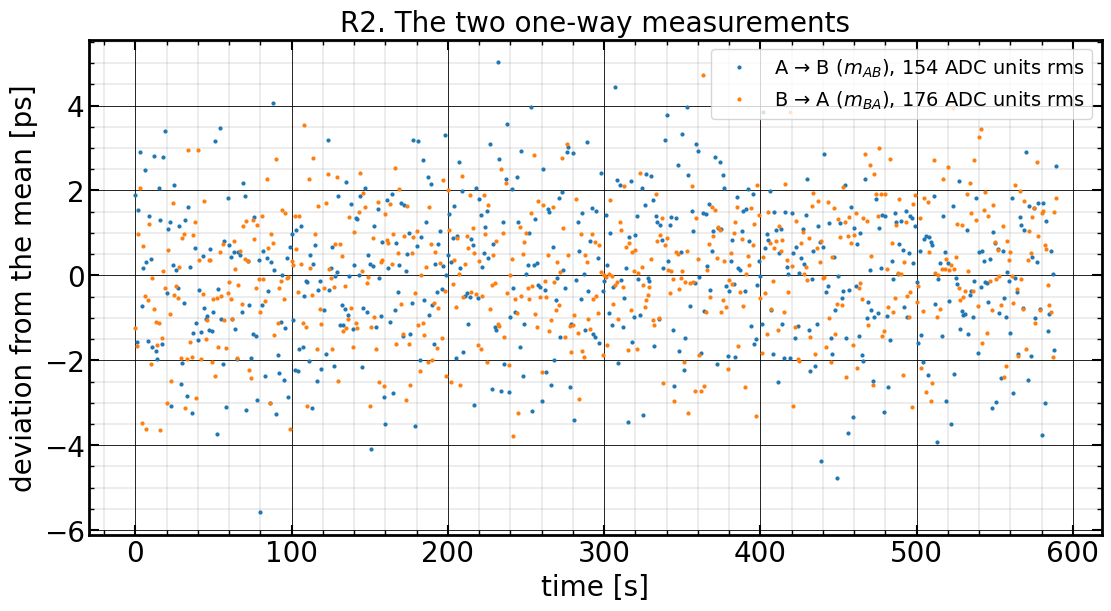

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (m_ab - m_ab.mean()) * 1e3, ".", ms=4, color="tab:blue", label=f"A → B ($m_{{AB}}$), {lvl_ab:.0f} ADC units rms")
ax.plot(t, (m_ba - m_ba.mean()) * 1e3, ".", ms=4, color="tab:orange", label=f"B → A ($m_{{BA}}$), {lvl_ba:.0f} ADC units rms")
ax.set_xlabel("time [s]"); ax.set_ylabel("deviation from the mean [ps]")
ax.set_title("R2. The two one-way measurements", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
save(fig, "report_R2_one_way"); plt.show()

In [28]:
display(Markdown(f"**Figure R2.** One-way measurements, each relative to its mean. A → B: {m_ab.std(ddof=1) * 1e3:.1f} ps standard deviation; B → A: {m_ba.std(ddof=1) * 1e3:.1f} ps, received {20 * np.log10(lvl_ba / lvl_ab):+.1f} dB relative to A → B."))

**Figure R2.** One-way measurements, each relative to its mean. A → B: 1.7 ps standard deviation; B → A: 1.5 ps, received +1.2 dB relative to A → B.

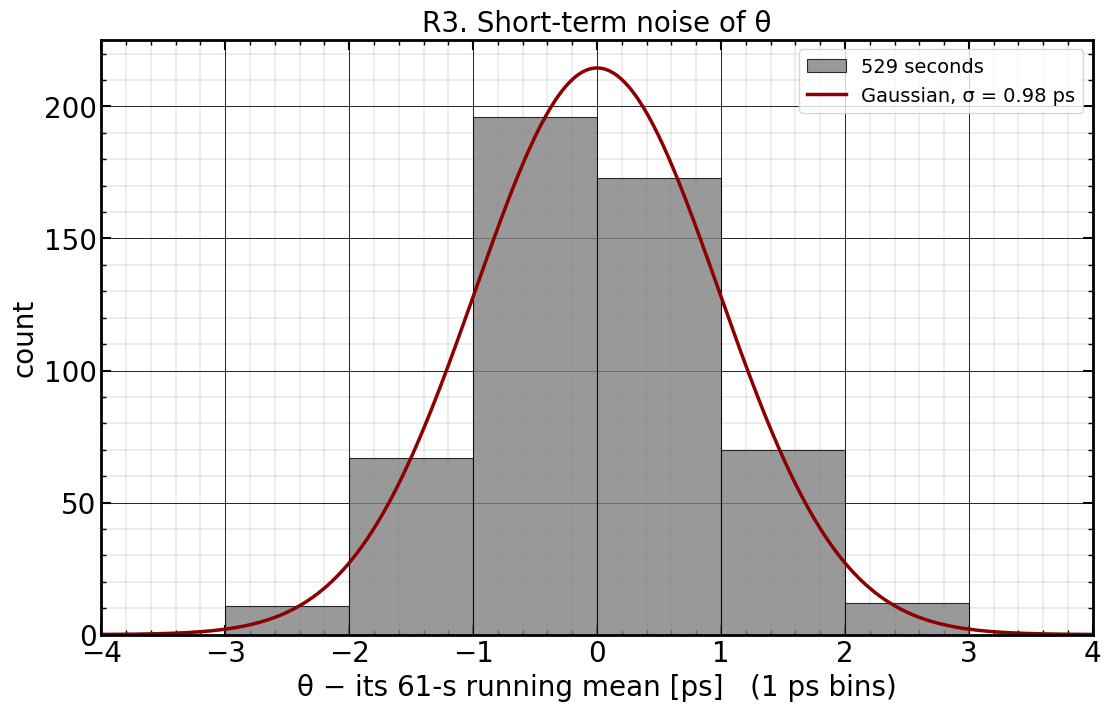

short-term residual sdev 0.98 ps, Shapiro-Wilk p = 0.94


In [29]:
BIN_R = 1.0
edge = BIN_R * np.ceil(np.abs(th_res).max() / BIN_R + 1)
bins = np.arange(-edge, edge + BIN_R / 2, BIN_R)
x = np.linspace(bins[0], bins[-1], 400)
sd_r = th_res.std(ddof=1)
fig, ax = plt.subplots(1, 1, figsize=(11, 7), layout='constrained')
ax.hist(th_res, bins=bins, color="grey", edgecolor="k", lw=0.8, alpha=0.8, label=f"{th_res.size} seconds")
ax.plot(x, th_res.size * BIN_R * stats.norm.pdf(x, 0, sd_r), "-", color="darkred", lw=2.5, label=f"Gaussian, σ = {sd_r:.2f} ps")
ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel(f"θ − its {res_win}-s running mean [ps]   ({BIN_R:.0f} ps bins)"); ax.set_ylabel("count")
ax.set_title("R3. Short-term noise of θ", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
save(fig, "report_R3_theta_noise"); plt.show()
print(f"short-term residual sdev {sd_r:.2f} ps, Shapiro-Wilk p = {stats.shapiro(th_res).pvalue:.2f}")

In [30]:
display(Markdown(f"**Figure R3.** Short-term noise of θ: each second minus the centred 61-s running mean, which removes slow wander. {sd_r:.2f} ps standard deviation: the precision of a single 1-second measurement with the present signal levels."))

**Figure R3.** Short-term noise of θ: each second minus the centred 61-s running mean, which removes slow wander. 0.98 ps standard deviation: the precision of a single 1-second measurement with the present signal levels.

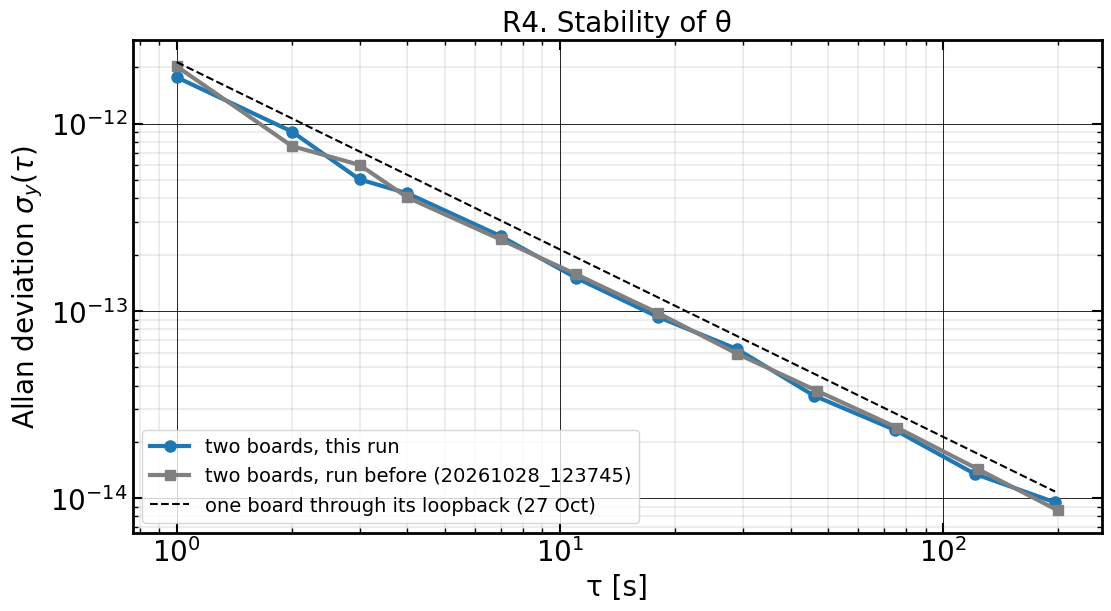

In [31]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(taus, ad, "o-", color="tab:blue", ms=8, label="two boards, this run")
ax.loglog(tausP, adP, "s-", color="grey", ms=7, label=f"two boards, run before ({PREV})")
ax.loglog(taus, 2.13e-12 / taus, "k--", lw=1.5, label="one board through its loopback (27 Oct)")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("R4. Stability of θ", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
save(fig, "report_R4_allan"); plt.show()

In [32]:
display(Markdown(f"**Figure R4.** Overlapping Allan deviation of θ: {ad[0]:.1e} at 1 s, {ad[-1]:.1e} at {taus[-1]} s. The one-board self-test through its own loopback is the dashed line ({2.13e-12:.1e}/τ); grey is the run before this one with the same set-up ({adP[0]:.1e} at 1 s)."))

**Figure R4.** Overlapping Allan deviation of θ: 1.8e-12 at 1 s, 9.5e-15 at 196 s. The one-board self-test through its own loopback is the dashed line (2.1e-12/τ); grey is the run before this one with the same set-up (2.0e-12 at 1 s).

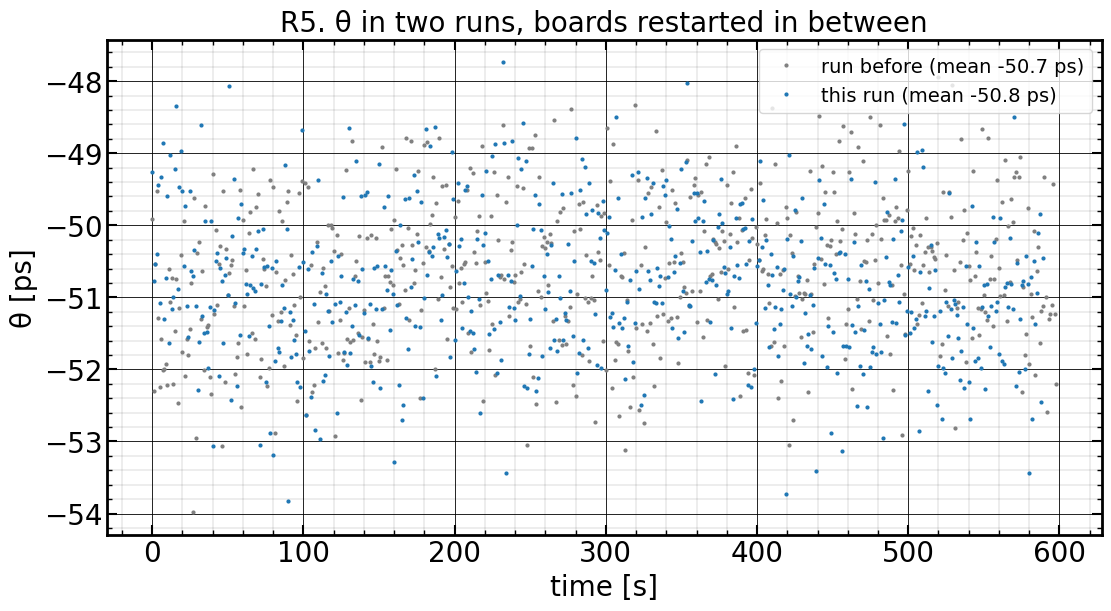

In [33]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(tP, th_p, ".", ms=4, color="grey", label=f"run before (mean {th_p.mean():+.1f} ps)")
ax.plot(t, th_ps, ".", ms=4, color="tab:blue", label=f"this run (mean {th_mean:+.1f} ps)")
ax.set_xlabel("time [s]"); ax.set_ylabel("θ [ps]")
ax.set_title("R5. θ in two runs, boards restarted in between", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
save(fig, "report_R5_repeat"); plt.show()

In [34]:
display(Markdown(f"**Figure R5.** θ in two 10-minute runs with the same set-up; between them both boards were restarted (overlay, clocks and MTS). Means {th_p.mean():+.2f} ps and {th_mean:+.2f} ps (standard errors {se(th_p):.2f} and {se(th_ps):.2f} ps), a difference of {th_mean - th_p.mean():+.2f} ps."))

**Figure R5.** θ in two 10-minute runs with the same set-up; between them both boards were restarted (overlay, clocks and MTS). Means -50.66 ps and -50.82 ps (standard errors 0.04 and 0.04 ps), a difference of -0.16 ps.